# Task 17 — A logistics knowledge layer: cross-table questions answered the same way twice

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Logistics Operations Database](https://www.kaggle.com/datasets/yogape/logistics-operations-database) — a fictional Class 8 trucking company, 2022–2024, 14 relational tables
**Task family:** knowledge graph (relational-to-RDF mapping, SHACL, SPARQL), deterministic question answering, a small tabular model · **Companion tasks:** `04_erp_document_rag.ipynb` (query understanding without an LLM), `01_aml_graph_triage.ipynb` (graphs)

---

## The task card

> **Board question.** *Our operations managers send about 40 cross-table questions a week to the analysts — which customer, which lane, which truck, how late — at an estimated 45 minutes of analyst time each. Can a knowledge layer answer 8 in 10 of them without an analyst, give the same number when a question is asked twice, and keep giving it after the source system changes?*

**Business context.** A carrier's transport management system (TMS) exports loads, trips, drivers, trucks, fuel and workshop records nightly; analysts join the export by hand, and two of them can return two numbers — one joins to last week's status, the other sums revenue after a join that repeats every load. The Sessions 07–09 answer is a knowledge graph rebuilt nightly (Session 01's *batch* pattern), validated before publication, and queried by an endpoint that answers what it understands and hands the rest back (*human-in-the-loop*). The legacy estate — TMS, fuel-card feed, workshop system, dashboards — will not change for the graph; the graph must survive *their* changes.

**What you will build from this notebook (see *Student tasks* at the end):**

1. a **knowledge graph** from a versioned mapping, with time-valid assignments, SHACL shapes and a build fingerprint;
2. a **competency-question suite** (SQL answers checked in SPARQL) as the CI gate;
3. a **question endpoint without an LLM** (template parser → SQL or SPARQL), with an operating point for what it answers, asks back or refers;
4. the given **fuel-cost model** (M2), packaged and reproducible, evaluated forward in time, and the evidence against a late-delivery model;
5. the **operational wrapper**: package, container, CI gate, MLflow, and monitoring that notices when the source changes meaning.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | The TMS export as legacy estate; nightly build plus online questions; who owns a definition such as "on time" |
| 2 · MLOps | Shapes and CQ suite as the CI gate; fingerprints; a 2024 holdout; price drift and a schema change |
| 3 · Semantic layer | The main deliverable: ontology, mapping, time-valid assignments, SHACL, competency questions (Sessions 07–09) |
| 4 · LLM/RAG | Stretch: natural language to SQL or SPARQL with an LLM, verified by re-running the query (Sessions 10–11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. As in Task 04 the baseline uses no LLM. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. Four **deliberate traps** are flagged ⚠ and measured in Section 6; turning each into a test is part of the task.

**Honesty note.** The data is **synthetic**: an unpublished simulator stitching independent random draws together with exact formulae. Keys, joins, validity and schema change are real problems here; prediction mostly is not, because most outcomes are noise.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, keys and the generator's fingerprints | Read. Its quirks go into your model card, shapes and data contract. |
| **B · The given model** | 3–6 | The knowledge graph and its shapes, the CQ suite, the rule-based parser and its operating point, the fuel-cost model, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The source after a schema change, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the change your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_tables` (Section 1); `materialise`, `fingerprint`, `validate` and `run_cq_suite` with its SQL and SPARQL query pairs (Section 3); `parse`, `answer_route` and `policy_table` (Section 4); `fit_predict` and `scores` (Section 5); `export_v2` (Section 6) and `psi` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** a Q4 2024 graph of 274,101 triples (fingerprint c29eaf9c847b); SQL and SPARQL agree on 10/10 competency questions; held-out parser accuracy 26.2 % (SQL) and 17.5 % (SPARQL), costing $996 a week against $1,350 for analysts only; fuel model trained on 40,104 loads, validated on 14,184 and tested on 28,656 in 2024, where M2 scores MAE $65.4 and bias +0.6 % against M0's $66.2 and −3.1 %.
- **Runtime:** about 2 minutes on a laptop (128 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, time, calendar, hashlib, warnings
from decimal import Decimal
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import lightgbm as lgb
import pyshacl
import rdflib
from rdflib import Graph, Namespace, Literal, RDF, RDFS, XSD
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 90)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "yogape/logistics-operations-database"
WINDOW_START, WINDOW_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2025-01-01")   # loads by load_date (the whole export)
TRAIN_END = pd.Timestamp("2023-07-01")    # fuel-cost model: train Feb 2022 – Jun 2023
VALID_END = pd.Timestamp("2024-01-01")    # validate Jul–Dec 2023 · holdout: all of 2024
KG_START, KG_END = pd.Timestamp("2024-10-01"), pd.Timestamp("2025-01-01")   # loads materialised in the graph (Q4 2024)
SCHEMA_V2_FROM = pd.Timestamp("2024-11-01")  # simulated TMS upgrade: source definitions change from this date (Sections 6–7)
ON_TIME_MIN_V1, ON_TIME_MIN_V2 = 120, 60     # delivery on-time window (± minutes) before / after the upgrade
QUESTIONS_PER_WEEK = 40                      # cross-table questions sent to the analysts (assumption — task C3)
ANALYST_MIN_PER_QUESTION = 45                # analyst time per question (assumption — task C3)
ANALYST_COST_PER_HOUR_USD = 45.0             # loaded analyst cost (assumption — task C3)
WRONG_ANSWER_COST_USD = 300.0                # a wrong number in a customer review or a lane-pricing call (assumption — task C3)
N_SLOTS_PER_INTENT = 4                       # golden set: slot fills per question intent (× 4 phrasings)
N_JOBS = 1                                   # LightGBM threads (the build machine is shared)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "logistics_ops", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

T_START = time.time()
print(f"pandas {pd.__version__} · duckdb {duckdb.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__} · lightgbm {lgb.__version__}")

pandas 3.1.0 · duckdb 2.0.0 · rdflib 7.6.0 · pyshacl 0.40.1 · lightgbm 4.7.0


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_tables`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `yogape/logistics-operations-database` (Yogape Rodriguez, version 1, November 2025) |
| **Licence** | MIT |
| **Provenance** | Synthetic; the generator is not published, so every number here describes the simulator, not trucking |
| **Size** | 60 MB, 549,706 rows: 85,410 loads and trips (one each), 170,820 stop events, 196,442 fuel purchases; master tables of 50–200 rows |
| **Files** | 14 CSVs, one per table, plus `DATABASE_SCHEMA.txt` (keys) |
| **Schema** | six master tables, six event tables and two monthly aggregates that reconcile exactly with trips |
| **Label** | none shipped; candidates are the delivery `on_time_flag` (noise, Section 5) and a load's fuel cost (used) |
| **Window used here** | all loads, 2022-01-01 to 2024-12-31 (stops and fuel spill into January 2025); the graph holds Q4 2024 (`KG_START`, `KG_END`); the model trains Feb 2022 – Jun 2023, validates Jul–Dec 2023, tests on 2024 |
| **PII** | synthetic driver names, licence numbers, dates of birth, fuel-card numbers and VINs: dropped on load. Customer names (fictional companies) are kept for entity linking |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Status columns are undated snapshots.** All 32 "Inactive" customers booked loads in 2024; none of the 26 terminated drivers or 28 non-active trucks ever appears on a trip. Joining to a status is a join without validity dates.
2. ⚠ **Trucks are double-booked**: 59.8 % of trips start before the truck's previous trip ends, 13.2 % of truck-months report utilisation above 1, and 486 trips are delivered before pick-up.
3. ⚠ **One load fans out** to one trip, two stop events and 0–11 fuel purchases; summing a load attribute after those joins multiplies it.
4. **Fuel purchases are not tied to consumption** (correlation 0.001 per trip); purchase locations and delivery facilities are random (3.9 % and 3.4 % consistent).
5. **Formulae, not measurements.** Gallons = miles ÷ mpg; revenue = rate card × uniform 0.85–1.15; mpg uniform on 5.5–7.5; on-time means |lateness| ≤ 120 minutes on a flat draw (44.6 % on time).
6. **Customer names are not keys**: 153 of 200 customers share 60 names (seven are "First Group").
7. **The fleet never changes**: the same 124 drivers, 92 trucks and 58 routes in each of 36 months; only the pump price moves.

In [2]:
TABLES = ["customers", "drivers", "trucks", "trailers", "facilities", "routes", "loads", "trips", "fuel_purchases",
          "maintenance_records", "delivery_events", "safety_incidents", "driver_monthly_metrics", "truck_utilization_metrics"]
PERSONAL = {"drivers": ["first_name", "last_name", "license_number", "date_of_birth"],   # synthetic, handled as if real
            "fuel_purchases": ["fuel_card_number"], "trucks": ["vin"], "trailers": ["vin"]}

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_tables() -> dict:
    '''Read the 14 CSVs once (DuckDB type inference), drop personal fields, cache one Parquet per table.'''
    out = {}
    for name in TABLES:
        cache = PROCESSED / f"17_{name}.parquet"
        if not cache.exists():
            df = duckdb.read_csv(str(get_raw(f"{name}.csv"))).df()
            df = df.drop(columns=PERSONAL.get(name, []))       # governance: personal fields never leave this function
            df.to_parquet(cache, index=False)
        out[name] = pd.read_parquet(cache)
    return out

def fmt_df(df, fmt):
    '''Format numbers for display (a light stand-in for DataFrame.style, which needs jinja2).'''
    out = df.copy().astype(object)
    for c in df.columns:
        f = fmt.get(c) if isinstance(fmt, dict) else fmt
        if f:
            out[c] = [f.format(v) if isinstance(v, (int, float, np.number)) and not isinstance(v, bool) and pd.notna(v) else v for v in df[c]]
    return out

t0 = time.time()
T = load_tables()
con = duckdb.connect()
for name, df in T.items():
    con.execute(f"CREATE OR REPLACE TABLE {name} AS SELECT * FROM df")
loads_in_window = T["loads"].load_date.between(WINDOW_START, WINDOW_END, inclusive="left").mean()
raw_mb = sum(get_raw(f"{t}.csv").stat().st_size for t in TABLES) / 1e6
print(f"{len(T)} tables ({raw_mb:.0f} MB of CSV) · {sum(len(d) for d in T.values()):,} rows · {len(T['loads']):,} loads ({loads_in_window:.0%} in window) · "
      f"{len(T['trips']):,} trips · {len(T['delivery_events']):,} stop events · {len(T['fuel_purchases']):,} fuel purchases · "
      f"{sum(d.memory_usage(deep=True).sum() for d in T.values())/1e6:.0f} MB · {time.time()-t0:.1f}s")

14 tables (60 MB of CSV) · 549,706 rows · 85,410 loads (100% in window) · 85,410 trips · 170,820 stop events · 196,442 fuel purchases · 77 MB · 0.9s


## 2 · First look: keys first, then the generator's fingerprints

*Part A · Explore · read; the keys and fingerprints it checks become shapes and data-contract rules.*

A graph is only as good as the keys its identifiers are minted from: is every primary key unique, does every foreign key resolve, and how often is it empty?

In [3]:
KEYS = {  # table: (primary key, {foreign key: parent table}) — from DATABASE_SCHEMA.txt, verified below
    "customers": (["customer_id"], {}), "drivers": (["driver_id"], {}), "trucks": (["truck_id"], {}),
    "trailers": (["trailer_id"], {}), "facilities": (["facility_id"], {}), "routes": (["route_id"], {}),
    "loads": (["load_id"], {"customer_id": "customers", "route_id": "routes"}),
    "trips": (["trip_id"], {"load_id": "loads", "driver_id": "drivers", "truck_id": "trucks", "trailer_id": "trailers"}),
    "fuel_purchases": (["fuel_purchase_id"], {"trip_id": "trips", "truck_id": "trucks", "driver_id": "drivers"}),
    "maintenance_records": (["maintenance_id"], {"truck_id": "trucks"}),
    "delivery_events": (["event_id"], {"trip_id": "trips", "load_id": "loads", "facility_id": "facilities"}),
    "safety_incidents": (["incident_id"], {"trip_id": "trips", "truck_id": "trucks", "driver_id": "drivers"}),
    "driver_monthly_metrics": (["driver_id", "month"], {"driver_id": "drivers"}),
    "truck_utilization_metrics": (["truck_id", "month"], {"truck_id": "trucks"}),
}
rows = []
for t, (pk, fks) in KEYS.items():
    df = T[t]
    fk = [f"{c} → {p} ({df[c].isna().mean():.0%} null, {int((~df[c].dropna().isin(T[p][KEYS[p][0][0]])).sum())} orphans)"
          for c, p in fks.items()]
    rows.append({"table": t, "rows": len(df), "cols": df.shape[1], "primary key": " + ".join(pk),
                 "PK unique": not df.duplicated(pk).any(), "foreign keys (null share, orphans)": "; ".join(fk) or "—"})
schema = pd.DataFrame(rows).set_index("table")
display(schema)
card = con.execute("""
    SELECT (SELECT COUNT(*) FROM trips) = (SELECT COUNT(DISTINCT load_id) FROM trips) AS one_trip_per_load,
           (SELECT MIN(n) FROM (SELECT COUNT(*) n FROM delivery_events GROUP BY trip_id)) AS min_events,
           (SELECT MAX(n) FROM (SELECT COUNT(*) n FROM delivery_events GROUP BY trip_id)) AS max_events,
           (SELECT COUNT(*) FROM trips WHERE trip_id NOT IN (SELECT trip_id FROM fuel_purchases)) AS trips_without_fuel,
           (SELECT MAX(n) FROM (SELECT COUNT(*) n FROM fuel_purchases GROUP BY trip_id)) AS max_fuel_per_trip,
           (SELECT MAX(actual_datetime) FROM delivery_events) AS last_stop,
           (SELECT MAX(purchase_date) FROM fuel_purchases) AS last_fuel""").df().iloc[0]
print(f"cardinalities · one trip per load: {bool(card.one_trip_per_load)} · stop events per trip: {card.min_events}–{card.max_events} · "
      f"fuel purchases per trip: 0–{card.max_fuel_per_trip} ({card.trips_without_fuel:,} trips have none) · "
      f"last stop {card.last_stop:%Y-%m-%d}, last fuel purchase {card.last_fuel:%Y-%m-%d}")

,rows,cols,primary key,PK unique,"foreign keys (null share, orphans)"
table,,,,,
customers,200,8,customer_id,True,—
drivers,150,8,driver_id,True,—
trucks,120,10,truck_id,True,—
trailers,180,8,trailer_id,True,—
facilities,50,9,facility_id,True,—
routes,58,9,route_id,True,—
loads,85410,12,load_id,True,"customer_id → customers (0% null, 0 orphans); route_id → routes (0% null, 0 orphans)"
trips,85410,12,trip_id,True,"load_id → loads (0% null, 0 orphans); driver_id → drivers (2% null, 0 orphans); truck_..."
fuel_purchases,196442,10,fuel_purchase_id,True,"trip_id → trips (0% null, 0 orphans); truck_id → trucks (2% null, 0 orphans); driver_i..."


cardinalities · one trip per load: True · stop events per trip: 2–2 · fuel purchases per trip: 0–11 (8,471 trips have none) · last stop 2025-01-03, last fuel purchase 2025-01-02


The keys hold: no duplicates, no orphans. Trips carry nullable driver, truck and trailer keys (2 % empty each), and a load fans out to two stops and up to eleven fuel purchases (Trap 2).

Synthetic data must earn trust before any model does: does a rule have exceptions, does a total reconcile, does the impossible happen — beside what a real TMS export would show?

In [4]:
LATE = "date_diff('microsecond', scheduled_datetime, actual_datetime) / 60e6"   # minutes late (negative = early)
TRIP_IV = """SELECT t.*, p.actual_datetime AS valid_from, d.actual_datetime AS valid_to
             FROM {S}.trips t JOIN {S}.delivery_events p ON p.trip_id = t.trip_id AND p.event_type = 'Pickup'
             JOIN {S}.delivery_events d ON d.trip_id = t.trip_id AND d.event_type = 'Delivery'"""
con.execute(f"CREATE OR REPLACE TABLE trip_iv AS {TRIP_IV.format(S='main')}")
con.execute("""CREATE OR REPLACE TABLE price_month AS
               SELECT date_trunc('month', purchase_date)::DATE AS month, ROUND(AVG(price_per_gallon), 3) AS price, COUNT(*) AS n
               FROM fuel_purchases GROUP BY 1""")
CHECKS = [   # (check, SQL returning one value, format, what a real TMS export would show)
    ("on_time_flag ⇔ |minutes late| ≤ 120, all 170,820 stop events",
     f"SELECT AVG(CASE WHEN on_time_flag = (ABS({LATE}) <= {ON_TIME_MIN_V1}) THEN 1 ELSE 0 END) FROM delivery_events", "pct", "a rule, plus exceptions"),
    ("delivery on-time rate", "SELECT AVG(on_time_flag::INT) FROM delivery_events WHERE event_type = 'Delivery'", "pct", "85–95 %"),
    ("fuel_gallons_used = miles ÷ mpg (to 0.05 gal)",
     "SELECT AVG(CASE WHEN ABS(fuel_gallons_used - actual_distance_miles / average_mpg) <= 0.05 THEN 1 ELSE 0 END) FROM trips", "pct", "close, not exact"),
    ("fuel_surcharge = typical miles × surcharge rate (to $0.01)",
     """SELECT AVG(CASE WHEN ABS(l.fuel_surcharge - r.typical_distance_miles * r.fuel_surcharge_rate) <= 0.01 THEN 1 ELSE 0 END)
        FROM loads l JOIN routes r USING (route_id)""", "pct", "tracks a weekly diesel index"),
    ("revenue inside 0.85–1.15 × rate card (miles × base rate)",
     """SELECT AVG(CASE WHEN l.revenue BETWEEN 0.85 * r.typical_distance_miles * r.base_rate_per_mile - 0.01
                                   AND 1.15 * r.typical_distance_miles * r.base_rate_per_mile + 0.01 THEN 1 ELSE 0 END)
        FROM loads l JOIN routes r USING (route_id)""", "pct", "long tails (spot spikes)"),
    ("corr(gallons bought on a trip, gallons the trip burned)",
     """SELECT CORR(f.g, t.fuel_gallons_used) FROM (SELECT trip_id, SUM(gallons) g FROM fuel_purchases GROUP BY 1) f
        JOIN trips t USING (trip_id)""", "num", "≈ 0.9"),
    ("fuel purchases whose city/state pair exists",
     """SELECT AVG(CASE WHEN (location_city, location_state) IN (SELECT (city, state) FROM facilities) THEN 1 ELSE 0 END)
        FROM fuel_purchases""", "pct", "≈ 100 %"),
    ("delivery events whose facility is in the event's own city",
     "SELECT AVG(CASE WHEN e.location_city = f.city THEN 1 ELSE 0 END) FROM delivery_events e JOIN facilities f USING (facility_id)",
     "pct", "≈ 100 %"),
    ("driver-months where driver_monthly_metrics matches trips (count and miles)",
     """SELECT AVG(CASE WHEN m.trips_completed = a.n AND m.total_miles = a.miles THEN 1 ELSE 0 END) FROM driver_monthly_metrics m
        JOIN (SELECT driver_id, date_trunc('month', dispatch_date)::DATE AS mon, COUNT(*) AS n, SUM(actual_distance_miles) AS miles
              FROM trips WHERE driver_id IS NOT NULL GROUP BY 1, 2) a ON a.driver_id = m.driver_id AND a.mon = m.month""",
     "pct", "≈ 100 % (it is derived)"),
    ("trips delivered before they were picked up", "SELECT COUNT(*) FROM trip_iv WHERE valid_to <= valid_from", "int", "0"),
    ("trips overlapping an earlier trip of the same truck",
     """SELECT AVG(CASE WHEN valid_from < prev_max_to THEN 1 ELSE 0 END) FROM (
          SELECT valid_from, MAX(valid_to) OVER (PARTITION BY truck_id ORDER BY valid_from, trip_id
                                                 ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS prev_max_to
          FROM trip_iv WHERE truck_id IS NOT NULL)""", "pct", "≈ 0 % (team swaps aside)"),
    ("truck-months with utilization_rate > 1", "SELECT AVG(CASE WHEN utilization_rate > 1 THEN 1 ELSE 0 END) FROM truck_utilization_metrics",
     "pct", "0 %"),
    ("trailers built more than a year after acquisition (of 180)",
     "SELECT COUNT(*) FROM trailers WHERE model_year > YEAR(acquisition_date) + 1", "int", "0"),
    ("terminated drivers with any trip (of 26)",
     "SELECT COUNT(DISTINCT driver_id) FROM trips WHERE driver_id IN (SELECT driver_id FROM drivers WHERE employment_status = 'Terminated')",
     "int", "most of them, before leaving"),
    ("non-active trucks with maintenance but no trip ever (of 28)",
     """SELECT COUNT(DISTINCT m.truck_id) FROM maintenance_records m JOIN trucks k USING (truck_id)
        WHERE k.status <> 'Active' AND m.truck_id NOT IN (SELECT truck_id FROM trips WHERE truck_id IS NOT NULL)""", "int", "few"),
    ("'Inactive' customers that booked loads in 2024 (of 32)",
     """SELECT COUNT(DISTINCT customer_id) FROM loads JOIN customers USING (customer_id)
        WHERE account_status = 'Inactive' AND load_date >= DATE '2024-01-01'""", "int", "few"),
    ("customers sharing their name with another customer (of 200)",
     """SELECT COUNT(*) || ' customers, ' || COUNT(DISTINCT customer_name) || ' names' FROM customers
        WHERE customer_name IN (SELECT customer_name FROM customers GROUP BY 1 HAVING COUNT(*) > 1)""", "str", "a handful"),
    ("drivers / trucks / routes active, every one of 36 months",
     """SELECT string_agg(DISTINCT v, ' | ') FROM (
          SELECT COUNT(DISTINCT driver_id) || ' / ' || COUNT(DISTINCT truck_id) || ' / ' || COUNT(DISTINCT l.route_id) AS v
          FROM trips JOIN loads l USING (load_id) GROUP BY date_trunc('month', dispatch_date))""", "str", "hires, retirements, new lanes"),
]
FMT = {"pct": "{:.1%}".format, "num": "{:.3f}".format, "int": "{:,}".format, "str": str}
art = pd.DataFrame([{"check": c, "observed": FMT[k](con.execute(s).fetchone()[0]), "a real TMS export": e} for c, s, k, e in CHECKS]).set_index("check")
display(art)

,observed,a real TMS export
check,,
"on_time_flag ⇔ |minutes late| ≤ 120, all 170,820 stop events",100.0%,"a rule, plus exceptions"
delivery on-time rate,44.6%,85–95 %
fuel_gallons_used = miles ÷ mpg (to 0.05 gal),99.9%,"close, not exact"
fuel_surcharge = typical miles × surcharge rate (to $0.01),100.0%,tracks a weekly diesel index
revenue inside 0.85–1.15 × rate card (miles × base rate),100.0%,long tails (spot spikes)
"corr(gallons bought on a trip, gallons the trip burned)",0.001,≈ 0.9
fuel purchases whose city/state pair exists,3.9%,≈ 100 %
delivery events whose facility is in the event's own city,3.4%,≈ 100 %
driver-months where driver_monthly_metrics matches trips (count and miles),100.0%,≈ 100 % (it is derived)


mean pump price by year: 2022 $4.20 · 2023 $3.85 · 2024 $3.65


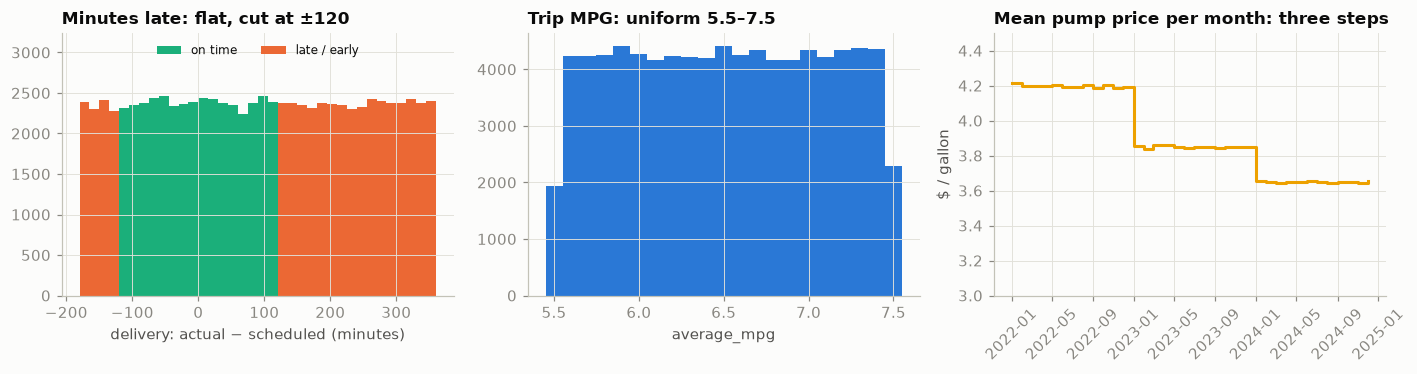

In [5]:
ev = con.execute(f"SELECT event_type, on_time_flag, {LATE} AS late FROM delivery_events").df()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
ax = axes[0]
d = ev[ev.event_type == "Delivery"]
bins = np.arange(-180, 361, 15)
ax.hist([d.late[d.on_time_flag], d.late[~d.on_time_flag]], bins=bins, stacked=True, color=[SERIES[2], SERIES[1]],
        label=["on time", "late / early"])
ax.set_title("Minutes late: flat, cut at ±120"); ax.set_xlabel("delivery: actual − scheduled (minutes)")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25); ax.legend(fontsize=8, loc="upper center", ncol=2)
ax = axes[1]
ax.hist(T["trips"].average_mpg, bins=np.arange(5.45, 7.6, 0.1), color=SERIES[0])
ax.set_title("Trip MPG: uniform 5.5–7.5"); ax.set_xlabel("average_mpg")
ax = axes[2]
pm = con.execute("SELECT * FROM price_month WHERE month < DATE '2025-01-01' ORDER BY month").df()
ax.step(pm.month, pm.price, where="post", lw=2, color=SERIES[3])
ax.set_ylim(3.0, 4.5); ax.set_title("Mean pump price per month: three steps"); ax.set_ylabel("$ / gallon"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
print("mean pump price by year:", " · ".join(f"{y} ${v:.2f}" for y, v in pm.groupby(pm.month.dt.year).price.mean().items()))

Three fingerprints: lateness drawn flat and cut at ±120 minutes, fuel economy that ignores truck, load and driver, and a pump price that changes only on New Year's Day. A model that looks good here has probably found a formula (Trap 3).

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The knowledge graph: mapping, time-valid assignments, shapes

*Part B · Given model · package `materialise`, `fingerprint`, `validate` and `run_cq_suite` unchanged; reproduce the build and CQ numbers (C2).*

Session 07 starts from the questions: the ten competency questions below fix what is mapped. Three design decisions:

- **Assignments carry a validity interval.** A trip is an `fl:Assignment` binding driver, truck and trailer to a load from pick-up (`fl:validFrom`) to delivery (`fl:validTo`); employment and the month's pump price are assignments too.
- **The mapping is declarative and versioned** (R2RML in spirit): one source query per class; it fails loudly when a column disappears, and its version is written into the graph.
- **Succession links are materialised**: `fl:nextOnTruck` makes "was this truck in two places at once?" a cheap check, not a quadratic search.

One quarter of loads keeps rdflib interactive on a laptop (task S2 widens it).

In [6]:
FL = Namespace("https://example.org/fleet#")       # the ontology (classes and properties)
ID = Namespace("https://example.org/fleet/id/")    # instances, keyed by the source system's identifiers
NS = {"fl": FL, "id": ID, "xsd": XSD, "rdfs": RDFS}

ONTOLOGY_TTL = """
@prefix fl: <https://example.org/fleet#> . @prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
fl:Customer a owl:Class . fl:Route a owl:Class . fl:Facility a owl:Class . fl:Load a owl:Class .
fl:Driver a owl:Class . fl:Truck a owl:Class . fl:Trailer a owl:Class .
fl:Assignment a owl:Class ; rdfs:comment "Anything true only between fl:validFrom and fl:validTo." .
fl:Trip rdfs:subClassOf fl:Assignment ; rdfs:comment "Driver + truck + trailer bound to one load, from pickup to delivery." .
fl:Employment rdfs:subClassOf fl:Assignment ; rdfs:comment "A driver's employment interval (hire to termination)." .
fl:FuelPricePeriod rdfs:subClassOf fl:Assignment ; rdfs:comment "The pump price in force for one calendar month." .
fl:Delivery a owl:Class . fl:FuelPurchase a owl:Class . fl:MaintenanceEvent a owl:Class .
fl:validFrom a owl:DatatypeProperty . fl:validTo a owl:DatatypeProperty .
fl:carries rdfs:domain fl:Trip ; rdfs:range fl:Load . fl:driver rdfs:domain fl:Trip ; rdfs:range fl:Driver .
fl:truck rdfs:domain fl:Trip ; rdfs:range fl:Truck . fl:trailer rdfs:domain fl:Trip ; rdfs:range fl:Trailer .
fl:nextOnTruck rdfs:domain fl:Trip ; rdfs:range fl:Trip ; rdfs:comment "The truck's next trip by start time (succession link)." .
fl:forCustomer rdfs:domain fl:Load ; rdfs:range fl:Customer . fl:onRoute rdfs:domain fl:Load ; rdfs:range fl:Route .
fl:ofTrip rdfs:domain fl:Delivery ; rdfs:range fl:Trip . fl:atFacility rdfs:domain fl:Delivery ; rdfs:range fl:Facility .
fl:forTrip rdfs:domain fl:FuelPurchase ; rdfs:range fl:Trip . fl:onTruck rdfs:domain fl:MaintenanceEvent ; rdfs:range fl:Truck .
fl:employee rdfs:domain fl:Employment ; rdfs:range fl:Driver .
"""

WIN = "load_date >= $a AND load_date < $b"
TRIP_WIN = "trip_id IN (SELECT trip_id FROM {S}.trips WHERE dispatch_date >= $a AND dispatch_date < $b)"
MAPPING_V1 = [   # relational-to-RDF mapping (R2RML in spirit): one source query per class, columns → properties
    {"cls": "Customer", "sql": "SELECT customer_id AS id, customer_name, customer_type, account_status, contract_start_date FROM {S}.customers",
     "lit": {"label": ("customer_name", "str"), "customerType": ("customer_type", "str"),
             "statusAtExport": ("account_status", "str"), "contractStart": ("contract_start_date", "date")}},
    {"cls": "Driver", "sql": "SELECT driver_id AS id, home_terminal, employment_status FROM {S}.drivers",
     "lit": {"homeTerminal": ("home_terminal", "str"), "statusAtExport": ("employment_status", "str")}},
    {"cls": "Employment", "sql": "SELECT 'EMP_' || driver_id AS id, driver_id, hire_date, termination_date FROM {S}.drivers",
     "lit": {"validFrom": ("hire_date", "dateTime"), "validTo": ("termination_date", "dateTime")}, "ref": {"employee": "driver_id"}},
    {"cls": "Truck", "sql": "SELECT truck_id AS id, make, model_year, home_terminal, status, acquisition_date FROM {S}.trucks",
     "lit": {"make": ("make", "str"), "modelYear": ("model_year", "int"), "homeTerminal": ("home_terminal", "str"),
             "statusAtExport": ("status", "str"), "acquired": ("acquisition_date", "date")}},
    {"cls": "Trailer", "sql": "SELECT trailer_id AS id, trailer_type, model_year, acquisition_date FROM {S}.trailers",
     "lit": {"trailerType": ("trailer_type", "str"), "modelYear": ("model_year", "int"), "acquired": ("acquisition_date", "date")}},
    {"cls": "Route", "sql": """SELECT route_id AS id, origin_city, destination_city, typical_distance_miles, base_rate_per_mile,
                               origin_city || ' → ' || destination_city AS label FROM {S}.routes""",
     "lit": {"label": ("label", "str"), "originCity": ("origin_city", "str"), "destinationCity": ("destination_city", "str"),
             "typicalMiles": ("typical_distance_miles", "int"), "baseRatePerMile": ("base_rate_per_mile", "dec")}},
    {"cls": "Facility", "sql": "SELECT facility_id AS id, facility_name, facility_type, city FROM {S}.facilities",
     "lit": {"label": ("facility_name", "str"), "facilityType": ("facility_type", "str"), "city": ("city", "str")}},
    {"cls": "FuelPricePeriod", "sql": """SELECT 'PRICE_' || strftime(month, '%Y_%m') AS id, month, month + INTERVAL 1 MONTH AS month_end, price
                                        FROM price_month""",
     "lit": {"validFrom": ("month", "date"), "validTo": ("month_end", "date"), "pricePerGallon": ("price", "dec")}},
    {"cls": "Load", "sql": f"""SELECT load_id AS id, customer_id, route_id, load_date, load_type, weight_lbs, revenue, booking_type
                               FROM {{S}}.loads WHERE {WIN}""",
     "lit": {"loadDate": ("load_date", "date"), "loadType": ("load_type", "str"), "weightLbs": ("weight_lbs", "int"),
             "revenue": ("revenue", "money"), "bookingType": ("booking_type", "str")},
     "ref": {"forCustomer": "customer_id", "onRoute": "route_id"}},
    {"cls": "Trip", "sql": """SELECT trip_id AS id, load_id, driver_id, truck_id, trailer_id, valid_from, valid_to,
                                     actual_distance_miles, fuel_gallons_used,
                                     CASE WHEN truck_id IS NULL THEN NULL ELSE
                                          LEAD(trip_id) OVER (PARTITION BY truck_id ORDER BY valid_from, trip_id) END AS next_on_truck
                              FROM ({TRIP_IV}) WHERE dispatch_date >= $a AND dispatch_date < $b""",
     "lit": {"validFrom": ("valid_from", "dateTime"), "validTo": ("valid_to", "dateTime"),
             "miles": ("actual_distance_miles", "int"), "fuelGallons": ("fuel_gallons_used", "dec")},
     "ref": {"carries": "load_id", "driver": "driver_id", "truck": "truck_id", "trailer": "trailer_id", "nextOnTruck": "next_on_truck"}},
    {"cls": "Delivery", "sql": f"""SELECT 'DEL_' || trip_id AS id, trip_id, facility_id, location_city, scheduled_datetime,
                                         actual_datetime, on_time_flag, {LATE} AS minutes_late
                                  FROM {{S}}.delivery_events WHERE event_type = 'Delivery' AND {TRIP_WIN}""",
     "lit": {"locationCity": ("location_city", "str"), "scheduledAt": ("scheduled_datetime", "dateTime"),
             "actualAt": ("actual_datetime", "dateTime"), "onTime": ("on_time_flag", "bool"), "minutesLate": ("minutes_late", "dec6")},
     "ref": {"ofTrip": "trip_id", "atFacility": "facility_id"}},
    {"cls": "FuelPurchase", "sql": f"""SELECT fuel_purchase_id AS id, trip_id, purchase_date, gallons, total_cost
                                      FROM {{S}}.fuel_purchases WHERE {TRIP_WIN}""",
     "lit": {"purchasedAt": ("purchase_date", "dateTime"), "gallons": ("gallons", "dec"), "totalCost": ("total_cost", "money")},
     "ref": {"forTrip": "trip_id"}},
    {"cls": "MaintenanceEvent", "sql": """SELECT maintenance_id AS id, truck_id, maintenance_date, maintenance_type, total_cost
                                          FROM {S}.maintenance_records WHERE maintenance_date >= $a AND maintenance_date < $b""",
     "lit": {"date": ("maintenance_date", "date"), "maintenanceType": ("maintenance_type", "str"), "totalCost": ("total_cost", "money")},
     "ref": {"onTruck": "truck_id"}},
]
CONVERT = {
    "str": lambda v: Literal(str(v)),
    "int": lambda v: Literal(int(v), datatype=XSD.integer),
    "dec": lambda v: Literal(Decimal(f"{float(v):.3f}"), datatype=XSD.decimal),
    "dec6": lambda v: Literal(Decimal(f"{float(v):.6f}"), datatype=XSD.decimal),
    "money": lambda v: Literal(Decimal(f"{float(v):.2f}"), datatype=XSD.decimal),
    "bool": lambda v: Literal(bool(v)),
    "date": lambda v: Literal(pd.Timestamp(v).date(), datatype=XSD.date),
    "dateTime": lambda v: Literal(pd.Timestamp(v).to_pydatetime(), datatype=XSD.dateTime),
}

def materialise(mapping, schema="main", start=KG_START, end=KG_END, mapping_version="1.0") -> Graph:
    '''Run every source query of the mapping and turn rows into triples. Fails loudly if a mapped column is missing.'''
    g = Graph(); g.bind("fl", FL); g.bind("id", ID)
    g.parse(data=ONTOLOGY_TTL, format="turtle")
    g.add((ID.build, RDF.type, FL.Build)); g.add((ID.build, FL.sourceSchema, Literal(schema)))
    g.add((ID.build, FL.mappingVersion, Literal(mapping_version))); g.add((ID.build, FL.windowStart, Literal(start.date(), datatype=XSD.date)))
    for m in mapping:
        sql = m["sql"].replace("{TRIP_IV}", TRIP_IV).format(S=schema)
        df = (con.execute(sql, {"a": start.date(), "b": end.date()}) if "$a" in sql else con.execute(sql)).df()
        subj = [ID[x] for x in df["id"]]
        cls = FL[m["cls"]]
        for s in subj:
            g.add((s, RDF.type, cls))
        for prop, (col, kind) in m.get("lit", {}).items():
            p, conv = (RDFS.label if prop == "label" else FL[prop]), CONVERT[kind]
            for s, v in zip(subj, df[col].values):
                if not pd.isna(v):
                    g.add((s, p, conv(v)))
        for prop, col in m.get("ref", {}).items():
            p = FL[prop]
            for s, v in zip(subj, df[col].values):
                if isinstance(v, str):
                    g.add((s, p, ID[v]))
    return g

def fingerprint(g: Graph) -> str:
    return hashlib.sha256("\n".join(sorted(f"{s} {p} {o}" for s, p, o in g)).encode()).hexdigest()[:12]

t0 = time.time()
kg = materialise(MAPPING_V1)
KG_BUILD_S = time.time() - t0
by_class = pd.Series({m["cls"]: len(set(kg.subjects(RDF.type, FL[m["cls"]]))) for m in MAPPING_V1}, name="nodes")
print(f"knowledge graph v1 · window {KG_START:%Y-%m-%d} – {KG_END:%Y-%m-%d} · {len(kg):,} triples · built in {KG_BUILD_S:.1f}s · "
      f"fingerprint {fingerprint(kg)}")
print(by_class.to_dict())

knowledge graph v1 · window 2024-10-01 – 2025-01-01 · 274,101 triples · built in 8.3s · fingerprint c29eaf9c847b
{'Customer': 200, 'Driver': 150, 'Employment': 150, 'Truck': 120, 'Trailer': 180, 'Route': 58, 'Facility': 50, 'FuelPricePeriod': 37, 'Load': 7184, 'Trip': 7184, 'Delivery': 7184, 'FuelPurchase': 16524, 'MaintenanceEvent': 247}


**Shapes are the data contract.** The SPARQL-based shapes are *graph-level* — one query per build, the offending node returned as the value — because pySHACL runs a node-level SPARQL constraint once per focus node, which on rdflib turns one query into 7,184. Build time is monitored, so this is an architecture decision.

In [7]:
SHAPES_PREFIX = """@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix fl: <https://example.org/fleet#> . @prefix id: <https://example.org/fleet/id/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
fl: sh:declare [ sh:prefix "fl" ; sh:namespace "https://example.org/fleet#"^^xsd:anyURI ] .
"""
SHAPES = {
    "TripCrew": """fl:TripCrew a sh:NodeShape ; sh:targetClass fl:Trip ;
        sh:property [ sh:path fl:driver ; sh:minCount 1 ; sh:maxCount 1 ; sh:class fl:Driver ] ;
        sh:property [ sh:path fl:truck ; sh:minCount 1 ; sh:maxCount 1 ; sh:class fl:Truck ] ;
        sh:property [ sh:path fl:trailer ; sh:minCount 1 ; sh:maxCount 1 ; sh:class fl:Trailer ] .""",
    "TripInterval": """fl:TripInterval a sh:NodeShape ; sh:targetClass fl:Trip ;
        sh:property [ sh:path fl:validFrom ; sh:minCount 1 ; sh:datatype xsd:dateTime ; sh:lessThan fl:validTo ] .""",
    "LoadLinks": """fl:LoadLinks a sh:NodeShape ; sh:targetClass fl:Load ;
        sh:property [ sh:path fl:forCustomer ; sh:minCount 1 ; sh:maxCount 1 ; sh:class fl:Customer ] ;
        sh:property [ sh:path fl:onRoute ; sh:minCount 1 ; sh:maxCount 1 ; sh:class fl:Route ] ;
        sh:property [ sh:path fl:revenue ; sh:minCount 1 ; sh:datatype xsd:decimal ; sh:minExclusive 0 ] .""",
    # graph-level SPARQL constraints: one query per build, the offending node reported as sh:value (see the note above)
    "TruckDoubleBooked": """fl:TruckDoubleBooked a sh:NodeShape ; sh:targetNode id:build ;
        sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes fl: ; sh:message "truck starts a trip before its previous trip ended" ;
          sh:select "SELECT $this ?value WHERE { ?a fl:nextOnTruck ?value ; fl:validTo ?end . ?value fl:validFrom ?start . FILTER(?start < ?end) }" ] .""",
    "DriverEmployed": """fl:DriverEmployed a sh:NodeShape ; sh:targetNode id:build ;
        sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes fl: ; sh:message "trip starts outside the driver's employment interval" ;
          sh:select "SELECT $this ?value WHERE { ?value fl:driver ?d ; fl:validFrom ?s . ?e fl:employee ?d ; fl:validFrom ?h . OPTIONAL { ?e fl:validTo ?x } FILTER(?s < ?h || (BOUND(?x) && ?s >= ?x)) }" ] .""",
    "DeliveryFacilityCity": """fl:DeliveryFacilityCity a sh:NodeShape ; sh:targetNode id:build ;
        sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes fl: ; sh:message "delivery recorded at a facility in another city" ;
          sh:select "SELECT $this ?value WHERE { ?value fl:atFacility ?f ; fl:locationCity ?c . ?f fl:city ?fc . FILTER(?c != ?fc) }" ] .""",
    "TrailerAge": """fl:TrailerAge a sh:NodeShape ; sh:targetNode id:build ;
        sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes fl: ; sh:message "trailer model year is after its acquisition year + 1" ;
          sh:select "SELECT $this ?value WHERE { ?value a fl:Trailer ; fl:modelYear ?y ; fl:acquired ?d . FILTER(?y > YEAR(?d) + 1) }" ] .""",
    "RateCard": """fl:RateCard a sh:NodeShape ; sh:targetNode id:build ;
        sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes fl: ; sh:message "load revenue outside 0.85–1.15 × miles × base rate" ;
          sh:select "SELECT $this ?value WHERE { ?value fl:onRoute ?rt ; fl:revenue ?r . ?rt fl:typicalMiles ?m ; fl:baseRatePerMile ?b . FILTER(?r < 0.85 * ?m * ?b - 0.01 || ?r > 1.15 * ?m * ?b + 0.01) }" ] .""",
    "OnTimeDefinition": """fl:OnTimeDefinition a sh:NodeShape ; sh:targetNode id:build ;
        sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes fl: ; sh:message "on-time flag disagrees with the ±120-minute definition" ;
          sh:select "SELECT $this ?value WHERE { ?value a fl:Delivery ; fl:onTime ?ot ; fl:minutesLate ?m . FILTER(?ot != (?m >= -120 && ?m <= 120)) }" ] .""",
}
SH = Namespace("http://www.w3.org/ns/shacl#")

def validate(g: Graph, names) -> pd.DataFrame:
    '''Run the named shapes with pySHACL; count violations per shape (sh:sourceShape of a property shape → its node shape).'''
    sg = Graph().parse(data=SHAPES_PREFIX + "\n".join(SHAPES[n] for n in names), format="turtle")
    parent = {o: s for s, o in sg.subject_objects(SH.property)}
    t = time.time()
    conforms, rg, _ = pyshacl.validate(g, shacl_graph=sg, inference="none", advanced=True, allow_warnings=True, inplace=True)
    secs = time.time() - t
    counts = {}
    for r in rg.subjects(RDF.type, SH.ValidationResult):
        src = rg.value(r, SH.sourceShape)
        n = str(parent.get(src, src)).split("#")[-1]
        counts[n] = counts.get(n, 0) + 1
    return pd.DataFrame({"violations": pd.Series({n: counts.get(n, 0) for n in names})}), secs

viol, shacl_s = validate(kg, list(SHAPES))
focus = {"TripCrew": "Trip", "TripInterval": "Trip", "LoadLinks": "Load", "TruckDoubleBooked": "Trip", "DriverEmployed": "Trip",
         "DeliveryFacilityCity": "Delivery", "TrailerAge": "Trailer", "RateCard": "Load", "OnTimeDefinition": "Delivery"}
viol["checked nodes"] = [len(set(kg.subjects(RDF.type, FL[focus[n]]))) for n in viol.index]
viol["share"] = viol.violations / viol["checked nodes"]
print(f"pySHACL · {len(SHAPES)} shapes over {len(kg):,} triples in {shacl_s:.0f}s")
display(fmt_df(viol, {"violations": "{:,}", "checked nodes": "{:,}", "share": "{:.1%}"}))

pySHACL · 9 shapes over 274,101 triples in 25s


,violations,checked nodes,share
TripCrew,414,"7,184",5.8%
TripInterval,43,"7,184",0.6%
LoadLinks,0,"7,184",0.0%
TruckDoubleBooked,"3,763","7,184",52.4%
DriverEmployed,0,"7,184",0.0%
DeliveryFacilityCity,"6,944","7,184",96.7%
TrailerAge,76,180,42.2%
RateCard,0,"7,184",0.0%
OnTimeDefinition,0,"7,184",0.0%


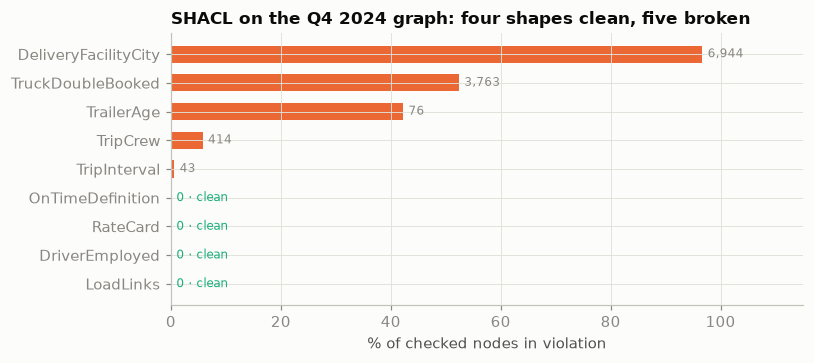

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
v = viol.sort_values("share")
ax.barh(v.index, v.share * 100, color=[SERIES[1] if x > 0 else SERIES[2] for x in v.violations], height=0.6)
for i, (s, n) in enumerate(zip(v.share, v.violations)):
    ax.text(s * 100 + 1, i, f"{n:,}" if n else "0 · clean", va="center", fontsize=8, color=MUTED if n else SERIES[2])
ax.set_xlim(0, 115); ax.set_xlabel("% of checked nodes in violation")
ax.set_title("SHACL on the Q4 2024 graph: four shapes clean, five broken")
plt.tight_layout()

**Clean** (green): links, employment intervals, and the revenue and on-time definitions — redundant-looking today, essential in Section 7. **Broken**: 52.4 % of trips overlap the truck's previous one, 96.7 % of deliveries sit at a facility in another city, 42.2 % of trailers postdate their purchase, 414 trips miss crew or equipment, 43 end before they start.

**Competency questions.** Each has an expected answer in SQL on the export, checked by SPARQL on the graph: two independent implementations that must agree.

In [9]:
def in_window(*dates) -> bool:
    return all(KG_START <= pd.Timestamp(d) < KG_END for d in dates)

def sparql(query: str, g=None):
    return list((g or kg).query(query, initNs=NS))

def num(x, nd=2):
    return None if x is None else round(float(x), nd)

def fdate(d) -> str:
    return f'"{pd.Timestamp(d).date()}"^^xsd:date'

# One SQL and one SPARQL implementation per question intent. Slots: customer, route, driver, truck, make, city, start, end, instant.
def sql_loads_customer(s, S="main"):
    return con.execute(f"SELECT COUNT(*) FROM {S}.loads WHERE customer_id = $c AND load_date >= $a AND load_date < $b",
                       {"c": s["customer"], "a": s["start"], "b": s["end"]}).fetchone()[0]
def rq_loads_customer(s, g=None):
    r = sparql(f"""SELECT (COUNT(?l) AS ?n) WHERE {{ ?l a fl:Load ; fl:forCustomer id:{s['customer']} ; fl:loadDate ?d .
                  FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return int(r[0][0])

def sql_lane_revenue(s, S="main"):
    return num(con.execute(f"SELECT SUM(revenue) FROM {S}.loads WHERE route_id = $r AND load_date >= $a AND load_date < $b",
                           {"r": s["route"], "a": s["start"], "b": s["end"]}).fetchone()[0])
def rq_lane_revenue(s, g=None):
    r = sparql(f"""SELECT (SUM(?v) AS ?x) WHERE {{ ?l fl:onRoute id:{s['route']} ; fl:loadDate ?d ; fl:revenue ?v .
                  FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return num(r[0][0])

def sql_ontime_driver(s, S="main"):
    return num(con.execute(f"""SELECT AVG(e.on_time_flag::INT) FROM {S}.trips t JOIN {S}.delivery_events e
                               ON e.trip_id = t.trip_id AND e.event_type = 'Delivery'
                               WHERE t.driver_id = $d AND t.dispatch_date >= $a AND t.dispatch_date < $b""",
                           {"d": s["driver"], "a": s["start"], "b": s["end"]}).fetchone()[0], 4)
def rq_ontime_driver(s, g=None):
    r = sparql(f"""SELECT (AVG(IF(?ot, 1, 0)) AS ?x) WHERE {{ ?t fl:driver id:{s['driver']} ; fl:carries/fl:loadDate ?d . ?e fl:ofTrip ?t ; fl:onTime ?ot . FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return num(r[0][0], 4)

def sql_top_truck(s, S="main"):
    return con.execute(f"""SELECT truck_id FROM {S}.trips WHERE truck_id IS NOT NULL AND dispatch_date >= $a AND dispatch_date < $b
                          GROUP BY 1 ORDER BY SUM(actual_distance_miles) DESC, truck_id LIMIT 1""",
                       {"a": s["start"], "b": s["end"]}).fetchone()[0]
def rq_top_truck(s, g=None):
    r = sparql(f"""SELECT ?k (SUM(?m) AS ?x) WHERE {{ ?t fl:truck ?k ; fl:miles ?m ; fl:carries/fl:loadDate ?d .
                  FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }} GROUP BY ?k ORDER BY DESC(?x) ?k LIMIT 1""", g)
    return str(r[0][0]).split("/")[-1]

def sql_maint_make(s, S="main"):
    return num(con.execute(f"""SELECT SUM(m.total_cost) FROM {S}.maintenance_records m JOIN {S}.trucks k USING (truck_id)
                               WHERE k.make = $k AND m.maintenance_date >= $a AND m.maintenance_date < $b""",
                           {"k": s["make"], "a": s["start"], "b": s["end"]}).fetchone()[0])
def rq_maint_make(s, g=None):
    r = sparql(f"""SELECT (SUM(?c) AS ?x) WHERE {{ ?m fl:onTruck ?k ; fl:totalCost ?c ; fl:date ?d . ?k fl:make "{s['make']}" .
                  FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return num(r[0][0])

def sql_reefer_terminal(s, S="main"):
    return con.execute(f"""SELECT COUNT(*) FROM {S}.loads l JOIN {S}.trips t USING (load_id) JOIN {S}.trucks k USING (truck_id)
                          WHERE l.load_type = 'Refrigerated' AND k.home_terminal = $c AND l.load_date >= $a AND l.load_date < $b""",
                       {"c": s["city"], "a": s["start"], "b": s["end"]}).fetchone()[0]
def rq_reefer_terminal(s, g=None):
    r = sparql(f"""SELECT (COUNT(?l) AS ?n) WHERE {{ ?t fl:carries ?l ; fl:truck ?k . ?k fl:homeTerminal "{s['city']}" . ?l fl:loadType "Refrigerated" ; fl:loadDate ?d . FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return int(r[0][0])

def sql_fuel_customer(s, S="main"):
    return num(con.execute(f"""SELECT COALESCE(SUM(f.total_cost), 0) FROM {S}.fuel_purchases f JOIN {S}.trips t USING (trip_id)
                               JOIN {S}.loads l ON l.load_id = t.load_id
                               WHERE l.customer_id = $c AND l.load_date >= $a AND l.load_date < $b""",
                           {"c": s["customer"], "a": s["start"], "b": s["end"]}).fetchone()[0])
def rq_fuel_customer(s, g=None):
    r = sparql(f"""SELECT (SUM(?c) AS ?x) WHERE {{ ?f fl:forTrip ?t ; fl:totalCost ?c . ?t fl:carries ?l . ?l fl:forCustomer id:{s['customer']} ; fl:loadDate ?d . FILTER(?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return num(r[0][0] if r and r[0][0] is not None else 0)

def sql_driver_at(s, S="main"):
    rows = con.execute(f"""SELECT DISTINCT driver_id FROM ({TRIP_IV.format(S=S)}) WHERE truck_id = $k AND driver_id IS NOT NULL
                           AND valid_from <= $i AND $i < valid_to ORDER BY 1""", {"k": s["truck"], "i": s["instant"]}).fetchall()
    return tuple(r[0] for r in rows)
def rq_driver_at(s, g=None):
    i = f'"{pd.Timestamp(s["instant"]).isoformat()}"^^xsd:dateTime'
    r = sparql(f"""SELECT DISTINCT ?d WHERE {{ ?t fl:truck id:{s['truck']} ; fl:driver ?d ; fl:validFrom ?a ; fl:validTo ?b .
                  FILTER(?a <= {i} && {i} < ?b) }} ORDER BY ?d""", g)
    return tuple(str(x[0]).split("/")[-1] for x in r)

def sql_lane_fuel_cost(s, S="main"):
    return num(con.execute(f"""SELECT SUM(t.fuel_gallons_used * p.price) FROM {S}.trips t JOIN {S}.loads l USING (load_id)
                               JOIN price_month p ON l.load_date >= p.month AND l.load_date < p.month + INTERVAL 1 MONTH
                               WHERE l.route_id = $r AND l.load_date >= $a AND l.load_date < $b""",
                           {"r": s["route"], "a": s["start"], "b": s["end"]}).fetchone()[0])
def rq_lane_fuel_cost(s, g=None):
    r = sparql(f"""SELECT (SUM(?gal * ?p) AS ?x) WHERE {{ ?t fl:carries ?l ; fl:fuelGallons ?gal . ?l fl:onRoute id:{s['route']} ; fl:loadDate ?d . ?pp a fl:FuelPricePeriod ; fl:validFrom ?f ; fl:validTo ?u ; fl:pricePerGallon ?p .
                  FILTER(?d >= ?f && ?d < ?u && ?d >= {fdate(s['start'])} && ?d < {fdate(s['end'])}) }}""", g)
    return num(r[0][0])

def sql_double_booked(s, S="main"):
    return con.execute(f"""SELECT COUNT(DISTINCT truck_id) FROM (
                             SELECT truck_id, valid_to, LEAD(valid_from) OVER (PARTITION BY truck_id ORDER BY valid_from, trip_id) AS nxt
                             FROM ({TRIP_IV.format(S=S)}) WHERE truck_id IS NOT NULL AND dispatch_date >= $a AND dispatch_date < $b)
                          WHERE nxt < valid_to""", {"a": s["start"], "b": s["end"]}).fetchone()[0]
def rq_double_booked(s, g=None):
    r = sparql(f"""SELECT (COUNT(DISTINCT ?k) AS ?n) WHERE {{ ?a fl:truck ?k ; fl:nextOnTruck ?b ; fl:validTo ?e ; fl:carries/fl:loadDate ?da . ?b fl:validFrom ?f ; fl:carries/fl:loadDate ?db . FILTER(?f < ?e && ?da >= {fdate(s['start'])} && ?db >= {fdate(s['start'])}
                  && ?da < {fdate(s['end'])} && ?db < {fdate(s['end'])}) }}""", g)
    return int(r[0][0])

INTENTS = {n: (globals()[f"sql_{n}"], globals()[f"rq_{n}"]) for n in
           ["loads_customer", "lane_revenue", "ontime_driver", "top_truck", "maint_make", "reefer_terminal",
            "fuel_customer", "driver_at", "lane_fuel_cost", "double_booked"]}

def same(a, b) -> bool:
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return abs(a - b) <= 0.011
    return a == b

In [10]:
q4 = (KG_START.date(), KG_END.date()); nov = (pd.Timestamp("2024-11-01").date(), pd.Timestamp("2024-12-01").date())
dec = (pd.Timestamp("2024-12-01").date(), KG_END.date())
top_cust = con.execute("SELECT customer_id FROM loads WHERE load_date >= $a AND load_date < $b GROUP BY 1 ORDER BY COUNT(*) DESC, 1 LIMIT 1",
                       {"a": nov[0], "b": nov[1]}).fetchone()[0]
top_drv = con.execute("SELECT driver_id FROM trips WHERE dispatch_date >= $a AND dispatch_date < $b AND driver_id IS NOT NULL GROUP BY 1 ORDER BY COUNT(*) DESC, 1 LIMIT 1",
                      {"a": q4[0], "b": q4[1]}).fetchone()[0]
top_terminal = T["trucks"][T["trucks"].status == "Active"].home_terminal.value_counts().index[0]
probe = con.execute("""SELECT a.truck_id, b.valid_from, LEAST(a.valid_to, b.valid_to) AS overlap_end
                       FROM trip_iv a JOIN trip_iv b ON a.truck_id = b.truck_id AND a.trip_id < b.trip_id
                       AND b.valid_from > a.valid_from AND b.valid_from < a.valid_to
                       WHERE a.dispatch_date >= $a AND b.dispatch_date < $b AND a.driver_id IS NOT NULL AND b.driver_id IS NOT NULL
                       ORDER BY a.trip_id LIMIT 1""", {"a": nov[0], "b": nov[1]}).fetchone()
probe = (probe[0], (pd.Timestamp(probe[1]) + (pd.Timestamp(probe[2]) - pd.Timestamp(probe[1])) / 2).floor("min"))
CQS = pd.DataFrame([
    ("CQ1", "loads_customer", f"How many loads did {top_cust} ship in November 2024?", {"customer": top_cust, "start": nov[0], "end": nov[1]}),
    ("CQ2", "lane_revenue", "What revenue did the Atlanta → Chicago lane earn in Q4 2024?", {"route": "RTE00001", "start": q4[0], "end": q4[1]}),
    ("CQ3", "ontime_driver", f"What share of {top_drv}'s Q4 2024 deliveries were on time?", {"driver": top_drv, "start": q4[0], "end": q4[1]}),
    ("CQ4", "top_truck", "Which truck drove the most miles in December 2024?", {"start": dec[0], "end": dec[1]}),
    ("CQ5", "maint_make", "What did maintenance on Volvo trucks cost in Q4 2024?", {"make": "Volvo", "start": q4[0], "end": q4[1]}),
    ("CQ6", "reefer_terminal", f"How many refrigerated loads did {top_terminal}-based trucks haul in Q4 2024?", {"city": top_terminal, "start": q4[0], "end": q4[1]}),
    ("CQ7", "fuel_customer", f"What fuel was bought on {top_cust}'s loads in Q4 2024?", {"customer": top_cust, "start": q4[0], "end": q4[1]}),
    ("CQ8", "driver_at", f"Who was driving {probe[0]} at {probe[1]:%Y-%m-%d %H:%M}?", {"truck": probe[0], "instant": probe[1]}),
    ("CQ9", "lane_fuel_cost", "What did Atlanta → Chicago loads burn in fuel at the pump price in force, Q4 2024?", {"route": "RTE00001", "start": q4[0], "end": q4[1]}),
    ("CQ10", "double_booked", "How many trucks were on two trips at once in Q4 2024?", {"start": q4[0], "end": q4[1]}),
], columns=["cq", "intent", "question", "slots"]).set_index("cq")

def run_cq_suite(S="main", g=None, with_sparql=True):
    rows = []
    for cq, r in CQS.iterrows():
        f_sql, f_rq = INTENTS[r.intent]
        t = time.time()
        try:
            a_sql = f_sql(r.slots, S)
        except duckdb.Error as e:
            a_sql = f"ERROR: {type(e).__name__}"
        ms_sql = (time.time() - t) * 1000
        row = {"cq": cq, "question": r.question, "expected (SQL)": a_sql, "SQL ms": ms_sql}
        if with_sparql:
            t = time.time(); a_rq = f_rq(r.slots, g); ms_rq = (time.time() - t) * 1000
            row.update({"SPARQL": a_rq, "agree": same(a_sql, a_rq), "SPARQL ms": ms_rq})
        rows.append(row)
    return pd.DataFrame(rows).set_index("cq")

cq_v1 = run_cq_suite()
print(f"competency questions · SQL and SPARQL agree on {cq_v1.agree.sum()}/{len(cq_v1)} · median latency SQL {cq_v1['SQL ms'].median():.0f} ms, "
      f"SPARQL {cq_v1['SPARQL ms'].median():.0f} ms")
display(fmt_df(cq_v1, {"SQL ms": "{:.0f}", "SPARQL ms": "{:.0f}"}))

competency questions · SQL and SPARQL agree on 10/10 · median latency SQL 9 ms, SPARQL 87 ms


,question,expected (SQL),SQL ms,SPARQL,agree,SPARQL ms
cq,,,,,,
CQ1,How many loads did CUST00192 ship in November 2024?,25,2,25,True,92
CQ2,What revenue did the Atlanta → Chicago lane earn in Q4 2024?,159081.52,2,159081.52,True,48
CQ3,What share of DRV00078's Q4 2024 deliveries were on time?,0.4342,8,0.4342,True,82
CQ4,Which truck drove the most miles in December 2024?,TRK00085,4,TRK00085,True,1583
CQ5,What did maintenance on Volvo trucks cost in Q4 2024?,73649.78,5,73649.78,True,66
CQ6,How many refrigerated loads did Dallas-based trucks haul in Q4 2024?,236,13,236,True,3643
CQ7,What fuel was bought on CUST00192's loads in Q4 2024?,42524.62,11,42524.62,True,57
CQ8,Who was driving TRK00083 at 2024-11-01 15:16?,"(DRV00017, DRV00090, DRV00099)",19,"(DRV00017, DRV00090, DRV00099)",True,56
CQ9,"What did Atlanta → Chicago loads burn in fuel at the pump price in force, Q4 2024?",53561.46,9,53561.46,True,2040


All ten agree. CQ8 returns *three* drivers for one truck at one minute: the graph reproduces the double-booking that `TruckDoubleBooked` reports, so a question and the shape that qualifies its answer must ship together. SPARQL is about an order of magnitude slower than DuckDB, and takes seconds on group-bys over every trip (CQ4, CQ6, CQ9, CQ10).

## 4 · Plain-English questions without an LLM

*Part B · Given model · package `parse`, `answer_route` and `policy_table`; C3 asks you to own the answer, ask or refer policy.*

Task 04's lesson, one step further: once a question is parsed into an intent and slots, the answer is a query. The parser is deterministic — identifiers by pattern, names by gazetteer, periods by date patterns, intents by keyword rules written against a *development* set of phrasings — and reuses the CQ functions, so the two routes differ only in the engine. "First Group" names seven customers: the parser asks rather than guesses.

In [11]:
CITIES = sorted(set(T["routes"].origin_city) | set(T["routes"].destination_city) | set(T["trucks"].home_terminal), key=len, reverse=True)
MAKES = sorted(T["trucks"].make.unique())
NAME_TO_IDS = T["customers"].groupby(T["customers"].customer_name.str.lower()).customer_id.apply(sorted).to_dict()
LANE = {(r.origin_city, r.destination_city): r.route_id for r in T["routes"].itertuples()}
MONTHS = {m.lower(): i for i, m in enumerate(calendar.month_name) if m} | {m.lower(): i for i, m in enumerate(calendar.month_abbr) if m}
INTENT_RULES = [   # (intent, any of these words, entities it needs) — first match wins; written against the *dev* phrasings only
    ("driver_at", ["driving", "driver"], ["truck", "instant"]),
    ("ontime_driver", ["on-time", "on time"], ["driver"]),
    ("maint_make", ["maintenance"], ["make"]),
    ("lane_fuel_cost", ["fuel"], ["route"]),
    ("fuel_customer", ["fuel"], ["customer"]),
    ("top_truck", ["most miles"], []),
    ("double_booked", ["double-booked", "overlapping"], []),
    ("reefer_terminal", ["refrigerated"], ["city"]),
    ("lane_revenue", ["revenue"], ["route"]),
    ("loads_customer", ["loads"], ["customer"]),
]

def parse_period(q):
    ql = q.lower()
    if m := re.search(r"\bq([1-4])\s+(20\d\d)\b", ql):
        a = pd.Timestamp(int(m.group(2)), 3 * int(m.group(1)) - 2, 1); return a, a + pd.DateOffset(months=3)
    if m := re.search(r"\b(" + "|".join(sorted(MONTHS, key=len, reverse=True)) + r")\.?\s+(20\d\d)\b", ql):
        a = pd.Timestamp(int(m.group(2)), MONTHS[m.group(1)], 1); return a, a + pd.DateOffset(months=1)
    if m := re.search(r"\b(20\d\d)-(\d\d)\b(?!-\d)", ql):
        a = pd.Timestamp(int(m.group(1)), int(m.group(2)), 1); return a, a + pd.DateOffset(months=1)
    if m := re.search(r"\b(?:in|during)\s+(20\d\d)\b", ql):
        a = pd.Timestamp(int(m.group(1)), 1, 1); return a, a + pd.DateOffset(years=1)
    return None

def parse(q: str) -> dict:
    '''Deterministic query understanding: entities by id, gazetteer or date pattern; intent by keyword rule.'''
    ql, ents = q.lower(), {}
    if m := re.search(r"\bCUST\d{5}\b", q): ents["customer"] = [m.group()]
    else:
        names = [n for n in NAME_TO_IDS if n in ql]
        if names: ents["customer"] = NAME_TO_IDS[max(names, key=len)]
    for key, pat in [("driver", r"\bDRV\d{5}\b"), ("truck", r"\bTRK\d{5}\b")]:
        if m := re.search(pat, q): ents[key] = [m.group()]
    found = sorted((ql.find(c.lower()), c) for c in CITIES if c.lower() in ql)
    cities = [c for i, c in found if not any(i > j and c.lower() in d.lower() for j, d in found if d != c)]
    if cities: ents["city"] = [cities[0]]
    if len(cities) >= 2: ents["route"] = [LANE.get((cities[0], cities[1]))]
    if makes := [k for k in MAKES if k.lower() in ql]: ents["make"] = makes[:1]
    if m := re.search(r"\b(20\d\d-\d\d-\d\d)[ T](\d\d:\d\d)\b", q): ents["instant"] = [pd.Timestamp(f"{m.group(1)} {m.group(2)}")]
    period = parse_period(q)
    for intent, words, needs in INTENT_RULES:
        if any(w in ql for w in words) and all(n in ents for n in needs) and (period or "instant" in needs):
            slots = {n: ents[n][0] for n in needs}
            if "customer" in needs and len(ents["customer"]) > 1:
                return {"status": "ambiguous", "intent": intent, "candidates": ents["customer"]}
            if any(v is None for v in slots.values()):
                return {"status": "unknown entity", "intent": intent}
            if period: slots.update(start=period[0].date(), end=period[1].date())
            return {"status": "ok", "intent": intent, "slots": slots}
    return {"status": "not understood"}

for q in ["How many loads did First Group ship in November 2024?", CQS.loc["CQ2", "question"], CQS.loc["CQ8", "question"],
          "Which unit covered the highest mileage in Nov 2024?"]:
    print(f"{q!r:90s} → {parse(q)}")

'How many loads did First Group ship in November 2024?'                                    → {'status': 'ambiguous', 'intent': 'loads_customer', 'candidates': ['CUST00011', 'CUST00015', 'CUST00028', 'CUST00070', 'CUST00130', 'CUST00149', 'CUST00199']}
'What revenue did the Atlanta → Chicago lane earn in Q4 2024?'                             → {'status': 'ok', 'intent': 'lane_revenue', 'slots': {'route': 'RTE00001', 'start': datetime.date(2024, 10, 1), 'end': datetime.date(2025, 1, 1)}}
'Who was driving TRK00083 at 2024-11-01 15:16?'                                            → {'status': 'ok', 'intent': 'driver_at', 'slots': {'truck': 'TRK00083', 'instant': Timestamp('2024-11-01 15:16:00')}}
'Which unit covered the highest mileage in Nov 2024?'                                      → {'status': 'not understood'}


**A golden set the parser has not seen.** Generated from the data as in Task 04: ten intents × four slot fills × four phrasings. Two phrasings per intent are the development set; two were written separately and never used to tune the rules, the rule-based analogue of a forward-in-time split. One slot fill in four asks about 2023, outside the graph's window. Two limits: the truth comes from the same SQL functions as the SQL route, and the parser's author wrote the held-out phrasings, so the score measures *parser coverage*, not query correctness, and task E1 needs an independent writer.

In [12]:
DEV = {   # phrasings the parser rules were written against
    "loads_customer": ["How many loads did {cust} ship in {period}?", "Number of loads for {cust} in {period}?"],
    "lane_revenue": ["What was the revenue on the {o} to {d} lane in {period}?", "Total revenue from {o} to {d} in {period}?"],
    "ontime_driver": ["What was the on-time delivery rate for driver {drv} in {period}?", "On-time rate of {drv} in {period}?"],
    "top_truck": ["Which truck drove the most miles in {period}?", "Truck with the most miles in {period}?"],
    "maint_make": ["How much did we spend on maintenance for {make} trucks in {period}?", "Maintenance cost of {make} trucks in {period}?"],
    "reefer_terminal": ["How many refrigerated loads were hauled by trucks based in {city} in {period}?", "Refrigerated loads on {city}-based trucks in {period}?"],
    "fuel_customer": ["How much fuel did we buy for {cust}'s loads in {period}?", "Fuel spend on loads for {cust} in {period}?"],
    "driver_at": ["Who was driving truck {trk} at {ts}?", "Which driver had truck {trk} at {ts}?"],
    "lane_fuel_cost": ["What was the fuel cost at the pump price in force for the {o} to {d} lane in {period}?", "Fuel cost at the month's pump price for loads from {o} to {d} in {period}?"],
    "double_booked": ["How many trucks were double-booked in {period}?", "Number of trucks on overlapping trips in {period}?"],
}
HELD_OUT = {   # phrasings written separately, as a manager might type them; the parser was not tuned on these
    "loads_customer": ["How many shipments did we move for {cust} during {period}?", "Count {cust}'s loads, {period}."],
    "lane_revenue": ["How much did we bill on {o}–{d} in {period}?", "Revenue for loads {o} → {d}, {period}?"],
    "ontime_driver": ["How punctual was {drv} in {period}?", "What share of {drv}'s deliveries arrived on time in {period}?"],
    "top_truck": ["Which unit covered the highest mileage in {period}?", "Top truck by distance driven, {period}?"],
    "maint_make": ["What did {make} units cost us in repairs in {period}?", "{make} fleet maintenance spend, {period}?"],
    "reefer_terminal": ["How many reefer loads did the {city} terminal's trucks pull in {period}?", "Count of temperature-controlled loads moved by {city} trucks in {period}?"],
    "fuel_customer": ["What were fuel purchases on {cust} trips in {period}?", "Diesel cost for {cust}, {period}?"],
    "driver_at": ["Who was behind the wheel of {trk} on {ts_alt}?", "Driver assigned to {trk} at {ts}?"],
    "lane_fuel_cost": ["Estimate fuel cost for the {o}–{d} lane in {period} at the prevailing diesel price.", "How much would the fuel for {o} → {d} loads in {period} have cost at that month's price?"],
    "double_booked": ["How many trucks were assigned to two trips at once in {period}?", "Count trucks with clashing assignments in {period}."],
}
ORD = {1: "first", 2: "second", 3: "third", 4: "fourth"}
def render_period(kind, y, n, style):
    if kind == "quarter":
        return f"Q{n} {y}" if style == "dev" else f"the {ORD[n]} quarter of {y}"
    return f"{calendar.month_name[n]} {y}" if style == "dev" else [f"{calendar.month_abbr[n]} {y}", f"{y}-{n:02d}"][n % 2]

def period_bounds(kind, y, n):
    a = pd.Timestamp(y, 3 * n - 2 if kind == "quarter" else n, 1)
    return a.date(), (a + pd.DateOffset(months=3 if kind == "quarter" else 1)).date()

q4_trips = con.execute("SELECT * FROM trip_iv WHERE dispatch_date >= $a AND dispatch_date < $b AND truck_id IS NOT NULL",
                       {"a": KG_START.date(), "b": KG_END.date()}).df()
old_trips = con.execute("SELECT * FROM trip_iv WHERE YEAR(dispatch_date) = 2023 AND truck_id IS NOT NULL").df()
active_drivers = sorted(q4_trips.driver_id.dropna().unique())
gold = []
for intent in INTENTS:
    for k in range(N_SLOTS_PER_INTENT):
        inside = k < N_SLOTS_PER_INTENT - 1                     # the last slot fill of every intent asks about 2023
        if inside:
            kind, y = ["month", "month", "month", "quarter"][rng.integers(4)], 2024
            n = int(rng.integers(10, 13)) if kind == "month" else 4
        else:
            kind, y, n = "month", 2023, int(rng.integers(1, 13))
        a, b = period_bounds(kind, y, n)
        cust_id = T["customers"].customer_id.iloc[rng.integers(len(T["customers"]))]
        use_name = intent in ("loads_customer", "fuel_customer") and k % 2 == 1
        name = T["customers"].set_index("customer_id").customer_name[cust_id]
        rt = T["routes"].iloc[rng.integers(len(T["routes"]))]
        trip = (q4_trips if inside else old_trips).iloc[rng.integers(len(q4_trips if inside else old_trips))]
        instant = (trip.valid_from + (trip.valid_to - trip.valid_from) / 3).floor("min")
        slots = {"customer": cust_id, "route": rt.route_id, "driver": active_drivers[rng.integers(len(active_drivers))],
                 "make": MAKES[rng.integers(len(MAKES))], "city": top_terminal if k == 0 else T["trucks"].home_terminal.iloc[rng.integers(len(T["trucks"]))],
                 "truck": trip.truck_id, "instant": instant, "start": a, "end": b}
        needs = {"loads_customer": ["customer"], "lane_revenue": ["route"], "ontime_driver": ["driver"], "top_truck": [],
                 "maint_make": ["make"], "reefer_terminal": ["city"], "fuel_customer": ["customer"], "driver_at": ["truck", "instant"],
                 "lane_fuel_cost": ["route"], "double_booked": []}[intent]
        gslots = {x: slots[x] for x in needs} | ({} if intent == "driver_at" else {"start": a, "end": b})
        expect = "clarify" if use_name and len(NAME_TO_IDS[name.lower()]) > 1 else "answer"
        truth = INTENTS[intent][0](gslots) if expect == "answer" else None
        fill = {"cust": name if use_name else cust_id, "o": rt.origin_city, "d": rt.destination_city, "drv": slots["driver"],
                "make": slots["make"], "city": slots["city"], "trk": slots["truck"], "ts": f"{instant:%Y-%m-%d %H:%M}",
                "ts_alt": f"{instant:%d %b %Y at %H:%M}"}
        for split, bank in [("dev", DEV), ("held-out", HELD_OUT)]:
            for tmpl in bank[intent]:
                gold.append({"intent": intent, "split": split, "in_window": inside, "expect": expect, "truth": truth, "gold_slots": gslots,
                             "question": tmpl.format(period=render_period(kind, y, n, split), **fill)})
gold = pd.DataFrame(gold)
print(f"{len(gold)} questions · {gold.split.value_counts().to_dict()} · expect clarification: {(gold.expect == 'clarify').sum()} · "
      f"outside the graph window: {(~gold.in_window).sum()}")
display(gold.sample(6, random_state=1)[["intent", "split", "question", "expect", "truth"]])

160 questions · {'dev': 80, 'held-out': 80} · expect clarification: 8 · outside the graph window: 40


,intent,split,question,expect,truth
29,lane_revenue,dev,Total revenue from Philadelphia to Seattle in April 2023?,answer,226474.58
42,ontime_driver,held-out,How punctual was DRV00144 in Dec 2024?,answer,0.3636
14,loads_customer,held-out,How many shipments did we move for Metro Wholesale during Aug 2023?,clarify,None
91,reefer_terminal,held-out,Count of temperature-controlled loads moved by Dallas trucks in the fourth quarter of ...,answer,236
81,reefer_terminal,dev,Refrigerated loads on Dallas-based trucks in November 2024?,answer,68
19,lane_revenue,held-out,"Revenue for loads Houston → Portland, Dec 2024?",answer,232379.48


In [13]:
_cache = {}
def answer_route(p: dict, route: str):
    '''Run a parsed question through one route. Returns (outcome, answer, milliseconds or None if cached).'''
    if p["status"] == "ambiguous":
        return "asked to clarify", None, None
    if p["status"] != "ok":
        return "not understood", None, None
    s = p["slots"]
    if route == "SPARQL" and not in_window(*[s[k] for k in ("start", "instant") if k in s]):
        return "outside graph window", None, None
    key = (route, p["intent"], tuple(sorted((k, str(v)) for k, v in s.items())))
    if key in _cache:
        return "answered", _cache[key][0], None
    t = time.time()
    ans = INTENTS[p["intent"]][0 if route == "SQL" else 1](s)
    _cache[key] = (ans, (time.time() - t) * 1000)
    return "answered", ans, _cache[key][1]

rows = []
for g in gold.itertuples():
    p = parse(g.question)
    for route in ["SQL", "SPARQL"]:
        outcome, ans, ms = answer_route(p, route)
        if outcome == "answered":
            outcome = "correct" if (g.expect == "answer" and same(ans, g.truth)) else "wrong"
        elif outcome == "asked to clarify" and g.expect == "clarify":
            outcome = "clarified (correct)"
        rows.append({"intent": g.intent, "split": g.split, "route": route, "outcome": outcome, "ms": ms, "parse": p["status"],
                     "question": g.question})
for cq, r in CQS.iterrows():                       # the ten competency questions, as worded in Section 3
    p = parse(r.question)
    for route in ["SQL", "SPARQL"]:
        outcome, ans, ms = answer_route(p, route)
        if outcome == "answered":
            outcome = "correct" if same(ans, cq_v1.loc[cq, "expected (SQL)"]) else "wrong"
        rows.append({"intent": r.intent, "split": "CQ texts", "route": route, "outcome": outcome, "ms": ms, "parse": p["status"],
                     "question": r.question})
ev_nl = pd.DataFrame(rows)
ev_nl["ok"] = ev_nl.outcome.isin(["correct", "clarified (correct)"])
acc = ev_nl.pivot_table(index="route", columns="split", values="ok", aggfunc="mean")[["CQ texts", "dev", "held-out"]]
outcomes = ev_nl[ev_nl.split != "CQ texts"].groupby(["route", "split"]).outcome.value_counts(normalize=True).unstack().fillna(0)
RULE = {i: (w, n) for i, w, n in INTENT_RULES}
def diagnose(q, intent):
    '''Why the parser gave up, checked in the order the parser needs the pieces.'''
    if not any(w in q.lower() for w in RULE[intent][0]): return "intent word not in the rules"
    if intent == "driver_at":
        return "entity not recognised" if re.search(r"\b20\d\d-\d\d-\d\d[ T]\d\d:\d\d\b", q) else "time phrasing not recognised"
    return "entity not recognised" if parse_period(q) else "period phrasing not recognised"
fails = ev_nl[(ev_nl.route == "SQL") & (ev_nl.outcome == "not understood")]
fail_modes = fails.assign(reason=[diagnose(q, i) for q, i in zip(fails.question, fails.intent)]).groupby(["split", "reason"]).size().unstack(fill_value=0)
lat = ev_nl.dropna(subset=["ms"]).groupby("route").ms.describe()[["count", "50%", "max"]].rename(columns={"count": "distinct queries", "50%": "median ms", "max": "max ms"})
print("accuracy (correct answers + correct requests for clarification)"); display(fmt_df(acc, "{:.1%}"))
display(fmt_df(outcomes, "{:.1%}"))
print("why questions were not understood (SQL route; the SPARQL route uses the same parser)"); display(fail_modes)
display(fmt_df(lat, "{:.0f}"))
rep = [INTENTS[r.intent][0](r.slots) for _, r in CQS.iterrows()]
print(f"determinism · SQL route re-run on the 10 CQs: identical answers {sum(same(a, b) for a, b in zip(rep, cq_v1['expected (SQL)']))}/10")

accuracy (correct answers + correct requests for clarification)


split,CQ texts,dev,held-out
route,,,
SPARQL,90.0%,77.5%,17.5%
SQL,90.0%,100.0%,26.2%


outcome         clarified (correct) correct not understood outside graph window
route  split                                                                   
SPARQL dev                     5.0%   72.5%           0.0%                22.5%
       held-out                2.5%   15.0%          73.8%                 8.8%
SQL    dev                     5.0%   95.0%           0.0%                 0.0%
       held-out                2.5%   23.8%          73.8%                 0.0%

why questions were not understood (SQL route; the SPARQL route uses the same parser)


reason,intent word not in the rules,period phrasing not recognised
split,,
CQ texts,1,0
held-out,48,11


,distinct queries,median ms,max ms
route,,,
SPARQL,34,61,3876
SQL,43,9,30


determinism · SQL route re-run on the 10 CQs: identical answers 10/10


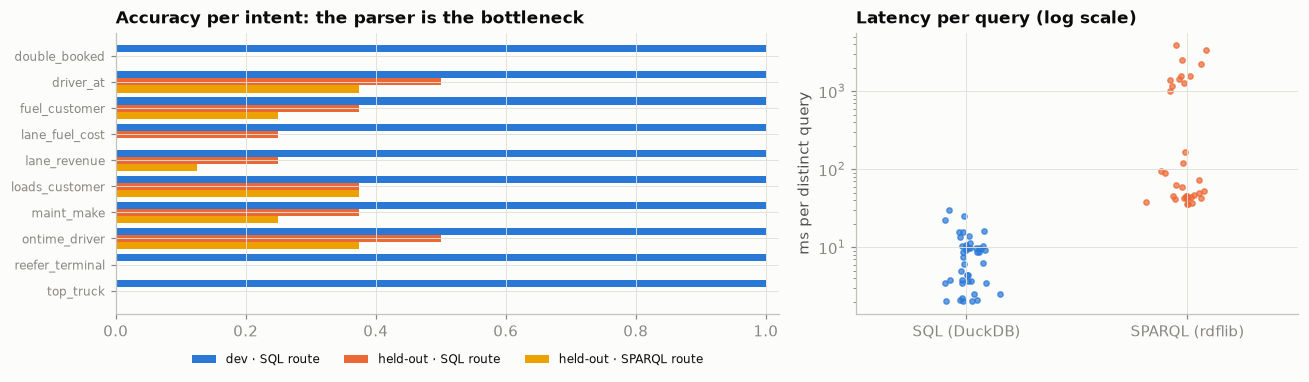

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
by_int = ev_nl.pivot_table(index="intent", columns=["split", "route"], values="ok", aggfunc="mean")
y = np.arange(len(by_int))
for j, (col, color) in enumerate([(("dev", "SQL"), SERIES[0]), (("held-out", "SQL"), SERIES[1]), (("held-out", "SPARQL"), SERIES[3])]):
    ax.barh(y + (j - 1) * 0.27, by_int[col], height=0.27, color=color, label=f"{col[0]} · {col[1]} route")
ax.set_yticks(y); ax.set_yticklabels(by_int.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1.02)
ax.set_title("Accuracy per intent: the parser is the bottleneck"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
ax = axes[1]
l = ev_nl.dropna(subset=["ms"])
for i, (route, color) in enumerate([("SQL", SERIES[0]), ("SPARQL", SERIES[1])]):
    v = l[l.route == route].ms.values
    ax.scatter(np.full(len(v), i) + rng.normal(0, 0.06, len(v)), v, s=12, color=color, alpha=0.7)
ax.set_yscale("log"); ax.set_xticks([0, 1]); ax.set_xticklabels(["SQL (DuckDB)", "SPARQL (rdflib)"]); ax.set_xlim(-0.5, 1.5)
ax.set_ylabel("ms per distinct query"); ax.set_title("Latency per query (log scale)")
plt.tight_layout()

On its development phrasings the SQL route is perfect and the SPARQL route loses exactly the 2023 questions. On the CQ texts both score 9 of 10 (CQ10 says "on two trips at once", not "double-booked"). On unseen phrasings accuracy collapses to 26.2 % (SQL) and 17.5 % (SPARQL): 48 failures are intent words the rules lack ("shipments", "punctual", "reefer", "diesel"), 11 are period phrasings ("the fourth quarter of 2024"). It **never answers wrongly** — every failure is a refusal or a clarification. The dev/held-out gap is task E1's ablation: the missing vocabulary belongs in the graph.

**The operating point: answer, ask or refer.** Unanswered questions go to an analyst; a wrong answer costs more. Two policies on the held-out rates, costs as assumed parameters (task C3): *ask or refer when unsure* (an ambiguous name goes back as a short list) and *always answer* (take the first match).

In [15]:
analyst_cost_q = ANALYST_MIN_PER_QUESTION / 60 * ANALYST_COST_PER_HOUR_USD
def policy_table(split):
    rows = []
    for route in ["SQL", "SPARQL"]:
        e = ev_nl[(ev_nl.split == split) & (ev_nl.route == route)]
        for policy in ["ask or refer when unsure", "always answer"]:
            wrong = (e.outcome == "wrong").mean()
            referred = e.outcome.isin(["not understood", "outside graph window"]).mean()   # these go to an analyst
            if policy == "always answer":            # ambiguous names: answer for the first match instead of asking the manager
                wrong += e.outcome.isin(["asked to clarify", "clarified (correct)"]).mean()
            auto = 1 - referred
            cost = QUESTIONS_PER_WEEK * (referred * analyst_cost_q + wrong * WRONG_ANSWER_COST_USD)
            rows.append({"route": route, "policy": policy, "answered without analyst": auto, "wrong answers": wrong,
                         "referred to analyst": referred, "cost per week $": cost})
    return pd.DataFrame(rows).set_index(["route", "policy"])
baseline_cost = QUESTIONS_PER_WEEK * analyst_cost_q
op = policy_table("held-out")
print(f"analyst only: {QUESTIONS_PER_WEEK} questions × ${analyst_cost_q:.2f} = ${baseline_cost:,.0f} per week · rates below from the held-out phrasings")
display(fmt_df(op, {"answered without analyst": "{:.0%}", "wrong answers": "{:.1%}", "referred to analyst": "{:.0%}", "cost per week $": "{:,.0f}"}))
op_dev = policy_table("dev")
print("same table on the dev phrasings (optimistic):", {f"{r}/{p}": f"${c:,.0f}" for (r, p), c in op_dev["cost per week $"].items()})

analyst only: 40 questions × $33.75 = $1,350 per week · rates below from the held-out phrasings


answered without analyst wrong answers referred to analyst cost per week $
route  policy                                                                                             
SQL    ask or refer when unsure                      26%          0.0%                 74%             996
       always answer                                 26%          2.5%                 74%           1,296
SPARQL ask or refer when unsure                      18%          0.0%                 82%           1,114
       always answer                                 18%          2.5%                 82%           1,414

same table on the dev phrasings (optimistic): {'SQL/ask or refer when unsure': '$0', 'SQL/always answer': '$600', 'SPARQL/ask or refer when unsure': '$304', 'SPARQL/always answer': '$904'}


On unseen phrasing the endpoint saves about a quarter of the analyst bill ($996 a week against $1,350): the honest figure, and far from the board's 8 in 10. *Always answer* is never better. As an answering engine SQL dominates SPARQL here; the graph earns its cost upstream — shapes, validity defined once, a mapping that absorbs a rename (Section 7).

## 5 · A small model, forward in time

*Part B · Given model · package `fit_predict` and `scores` unchanged and reproduce M2 against M0 (C2); the late-delivery model is reference only.*

The card proposed a late-delivery model. Test it as a sceptic would: LightGBM on everything known at booking, trained on Feb 2022 – Jun 2023, scored on 2024.

In [16]:
ml = con.execute("""
    SELECT l.load_id, l.load_date, l.load_type, l.weight_lbs, l.pieces, l.booking_type, c.customer_type, r.origin_city, r.destination_city,
           r.typical_distance_miles, r.typical_transit_days, t.driver_id, t.average_mpg, t.actual_distance_miles, t.fuel_gallons_used,
           hour(p.scheduled_datetime) AS pickup_hour, NOT e.on_time_flag AS late,
           pm.price AS price_in_force, pp.price AS price_prev_month, t.fuel_gallons_used * pm.price AS fuel_cost,
           dm.on_time_delivery_rate AS driver_month_on_time
    FROM loads l JOIN trips t USING (load_id) JOIN routes r USING (route_id) JOIN customers c USING (customer_id)
    JOIN delivery_events e ON e.trip_id = t.trip_id AND e.event_type = 'Delivery'
    JOIN delivery_events p ON p.trip_id = t.trip_id AND p.event_type = 'Pickup'
    JOIN price_month pm ON pm.month = date_trunc('month', l.load_date)
    JOIN price_month pp ON pp.month = date_trunc('month', l.load_date) - INTERVAL 1 MONTH
    LEFT JOIN driver_monthly_metrics dm ON dm.driver_id = t.driver_id AND dm.month = date_trunc('month', l.load_date)
    ORDER BY l.load_date, l.load_id""").df()
ml["month"] = ml.load_date.dt.month; ml["dow"] = ml.load_date.dt.dayofweek
for c in ["load_type", "booking_type", "customer_type", "origin_city", "destination_city"]:
    ml[c] = ml[c].astype("category")
BOOKING = ["typical_distance_miles", "typical_transit_days", "weight_lbs", "pieces", "load_type", "booking_type", "customer_type",
           "origin_city", "destination_city", "month", "dow"]
tr = ml.load_date < TRAIN_END; va = (ml.load_date >= TRAIN_END) & (ml.load_date < VALID_END); te = ml.load_date >= VALID_END
print(f"model table {len(ml):,} loads (Feb 2022 – Dec 2024) · train {tr.sum():,} · valid {va.sum():,} · holdout 2024 {te.sum():,}")

LGB_REG = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
               colsample_bytree=0.8, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
clf = lgb.LGBMClassifier(**LGB_REG).fit(ml.loc[tr, BOOKING + ["pickup_hour"]], ml.loc[tr, "late"])
auc_late = roc_auc_score(ml.loc[te, "late"], clf.predict_proba(ml.loc[te, BOOKING + ["pickup_hour"]])[:, 1])
print(f"late delivery · base rate {ml.late.mean():.1%} · LightGBM on booking-time features · 2024 ROC-AUC {auc_late:.3f}")

model table 82,944 loads (Feb 2022 – Dec 2024) · train 40,104 · valid 14,184 · holdout 2024 28,656


late delivery · base rate 55.4% · LightGBM on booking-time features · 2024 ROC-AUC 0.503


A ROC-AUC of 0.503 is chance: lateness is a dice roll with a 55.4 % chance of "late". **Do not build `POST /predict/late`**.

What *can* be modelled is the quote desk's question: **what will this load cost in fuel?** Target: the trip's gallons at the month's mean pump price. Three models, booking-time features only:

- **M0 · rate card**: lane miles ÷ 6.5 mpg × last month's price — the carrier's spreadsheet;
- **M1 · LightGBM on the dollar cost**, price-blind, so it must learn the price from the calendar;
- **M2 · LightGBM on gallons** × last month's price: the model learns physics, the price feed supplies the market.

In [17]:
def fit_predict(cols, target):
    m = lgb.LGBMRegressor(**LGB_REG).fit(ml.loc[tr, cols], ml.loc[tr, target])
    return m, m.predict(ml[cols])

preds = {"M0 · rate card (miles ÷ 6.5 mpg × last month's price)": ml.typical_distance_miles / 6.5 * ml.price_prev_month}
_, p1 = fit_predict(BOOKING, "fuel_cost");               preds["M1 · LightGBM on fuel cost (price-blind)"] = p1
_, p2 = fit_predict(BOOKING, "fuel_gallons_used");       preds["M2 · LightGBM on gallons × last month's price"] = p2 * ml.price_prev_month

def scores(mask):
    y = ml.loc[mask, "fuel_cost"]
    return {name: {"MAE $": np.abs(p[mask] - y).mean(), "bias %": (p[mask].mean() - y.mean()) / y.mean() * 100,
                   "MAPE %": (np.abs(p[mask] - y) / y).mean() * 100} for name, p in preds.items()}
res = pd.concat({"validation (Jul–Dec 2023)": pd.DataFrame(scores(va)).T, "holdout (2024)": pd.DataFrame(scores(te)).T}, axis=1)
print(f"mean fuel cost per load: 2023H2 ${ml.loc[va, 'fuel_cost'].mean():,.0f} · 2024 ${ml.loc[te, 'fuel_cost'].mean():,.0f}")
display(fmt_df(res, "{:.1f}"))

mean fuel cost per load: 2023H2 $855 · 2024 $805


validation (Jul–Dec 2023)               holdout (2024)              
                                                                          MAE $ bias % MAPE %          MAE $ bias % MAPE %
M0 · rate card (miles ÷ 6.5 mpg × last month's price)                      70.4   -3.7    8.0           66.2   -3.1    8.0
M1 · LightGBM on fuel cost (price-blind)                                   93.2    8.9   11.6          108.0   12.3   14.4
M2 · LightGBM on gallons × last month's price                              68.6   -0.1    8.1           65.4    0.6    8.2

2024 monthly bias % · M1: +5.7 +9.8 +10.8 +10.2 +10.8 +10.1 +14.9 +15.1 +15.5 +15.1 +15.2 +14.8
2024 monthly bias % · M2: +5.4 -0.1 +0.4 -0.3 +0.4 -0.2 +0.3 +0.0 +0.4 +0.1 +0.4 -0.1


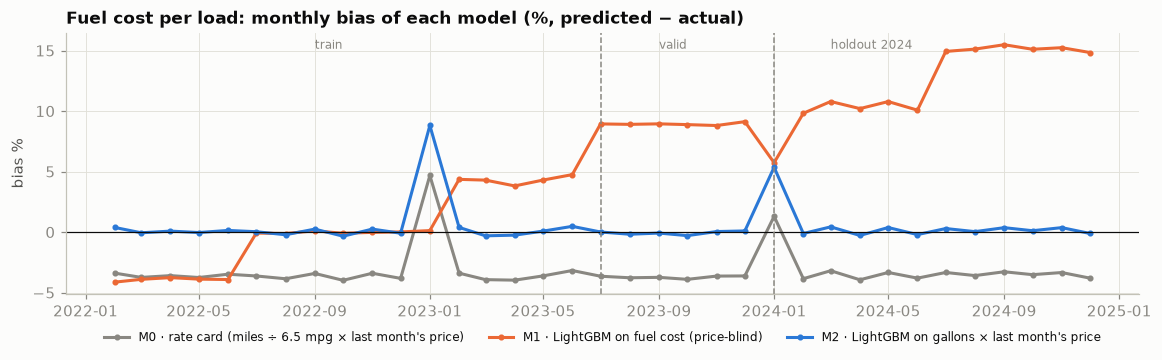

In [18]:
mon = ml.assign(m=ml.load_date.dt.to_period("M"))
fig, ax = plt.subplots(figsize=(11, 3.4))
for (name, p), color in zip(preds.items(), [MUTED, SERIES[1], SERIES[0]]):
    b = mon.assign(p=p).groupby("m").apply(lambda d: (d.p.mean() - d.fuel_cost.mean()) / d.fuel_cost.mean() * 100, include_groups=False)
    ax.plot(b.index.to_timestamp(), b.values, "-o", ms=3, lw=2, color=color, label=name)
ax.axhline(0, color=INK, lw=0.8)
for x in [TRAIN_END, VALID_END]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
top = ax.get_ylim()[1]
ax.text(pd.Timestamp("2022-09-01"), top * 0.92, "train", color=MUTED, fontsize=8)
ax.text(pd.Timestamp("2023-09-01"), top * 0.92, "valid", color=MUTED, fontsize=8)
ax.text(pd.Timestamp("2024-03-01"), top * 0.92, "holdout 2024", color=MUTED, fontsize=8)
ax.set_title("Fuel cost per load: monthly bias of each model (%, predicted − actual)"); ax.set_ylabel("bias %")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout()
for name, p in list(preds.items())[1:]:
    b = mon.assign(p=p)[mon.load_date >= VALID_END].groupby("m").apply(lambda d: (d.p.mean() - d.fuel_cost.mean()) / d.fuel_cost.mean() * 100, include_groups=False)
    print(f"2024 monthly bias % · {name.split(' · ')[0]}:", " ".join(f"{v:+.1f}" for v in b.values))

M1, trained while diesel averaged $4.20 and then $3.85, keeps quoting those prices: +12.3 % on 2024, worse from July, where its month feature has only seen 2022 prices. M2 separates what drifts (price) from what does not (gallons per mile) and stays within half a per cent from February; January's +5.4 % is last month's price lagging the New Year step. M2 beats the rate card on bias (+0.6 % against −3.1 %) but barely on MAE ($65.4 against $66.2): the remaining 8 % is the uniform mpg draw.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test, and `export_v2` feeds the CQ gate (C4).*

Four routes to a confident, wrong number, each measured.

**Trap 1 — joins without validity dates.** *What did 2022 fuel cost?*, priced at "the" fuel price instead of the price in force; and *who was driving truck X at time T?*, joined on the dispatch date instead of the assignment interval.

In [19]:
# Trap 1a — a price with no validity dates
fuel22 = con.execute("""SELECT SUM(t.fuel_gallons_used * p.price) AS in_force, SUM(t.fuel_gallons_used) AS gallons
                        FROM trips t JOIN price_month p ON p.month = date_trunc('month', t.dispatch_date) WHERE YEAR(t.dispatch_date) = 2022""").df().iloc[0]
latest = con.execute("SELECT price FROM price_month WHERE month = DATE '2024-12-01'").fetchone()[0]
overall = con.execute("SELECT AVG(price_per_gallon) FROM fuel_purchases").fetchone()[0]
print(f"2022 fuel cost · at the price in force ${fuel22.in_force/1e6:.2f} M · at 'the' price (latest month, ${latest:.2f}) ${fuel22.gallons*latest/1e6:.2f} M "
      f"({fuel22.gallons*latest/fuel22.in_force-1:+.1%}) · at the all-time average (${overall:.2f}) ${fuel22.gallons*overall/1e6:.2f} M ({fuel22.gallons*overall/fuel22.in_force-1:+.1%})")

# Trap 1b — "who had truck X at time T?" answered with the dispatch date instead of the assignment interval
prng = np.random.default_rng(SEED + 1)
probes = pd.DataFrame({"truck_id": prng.choice(sorted(T["trips"].truck_id.dropna().unique()), 2000),
                       "instant": pd.Timestamp("2024-01-01") + pd.to_timedelta(prng.uniform(0, 365 * 24 * 60, 2000).round(), unit="min")})
con.execute("CREATE OR REPLACE TABLE probes AS SELECT row_number() OVER () AS pid, * FROM probes")
cmp_ = con.execute("""
    WITH naive AS (SELECT p.pid, string_agg(DISTINCT t.driver_id, ',' ORDER BY t.driver_id) AS d FROM probes p LEFT JOIN trip_iv t
                   ON t.truck_id = p.truck_id AND t.dispatch_date = p.instant::DATE AND t.driver_id IS NOT NULL GROUP BY 1),
         valid AS (SELECT p.pid, string_agg(DISTINCT t.driver_id, ',' ORDER BY t.driver_id) AS d FROM probes p LEFT JOIN trip_iv t
                   ON t.truck_id = p.truck_id AND t.valid_from <= p.instant AND p.instant < t.valid_to AND t.driver_id IS NOT NULL GROUP BY 1)
    SELECT AVG(CASE WHEN coalesce(n.d, '') <> coalesce(v.d, '') THEN 1 ELSE 0 END) AS differ,
           AVG(CASE WHEN v.d IS NULL THEN 1 ELSE 0 END) AS idle, AVG(CASE WHEN v.d LIKE '%,%' THEN 1 ELSE 0 END) AS two_or_more
    FROM naive n JOIN valid v USING (pid)""").df().iloc[0]
print(f"2,000 (truck, instant) probes in 2024 · dispatch-date join gives a different driver set in {cmp_.differ:.0%} of probes · "
      f"interval join: truck idle in {cmp_.idle:.0%}, two or more drivers at once in {cmp_.two_or_more:.0%}")

2022 fuel cost · at the price in force $26.63 M · at 'the' price (latest month, $3.65) $23.18 M (-13.0%) · at the all-time average ($3.90) $24.73 M (-7.1%)
2,000 (truck, instant) probes in 2024 · dispatch-date join gives a different driver set in 61% of probes · interval join: truck idle in 40%, two or more drivers at once in 23%


The undated price misstates 2022 fuel by 13.0 % or 7.1 %; both look plausible. The dispatch-date join returns a different driver set in 61 % of probes: it misses yesterday's trips still on the road and invents trips that start later today. The interval join is right, and surfaces the artefact — two or more drivers on one truck at 23 % of instants. The fix belongs in the model, not in each query; CQ8 and CQ9 pin it.

**Trap 2 — double counting through one-to-many joins.** "Revenue and fuel spend per customer for 2024" in one query: loads → trips → fuel purchases, then sum both.

In [20]:
naive = con.execute("""SELECT SUM(l.revenue) AS revenue, SUM(f.total_cost) AS fuel, COUNT(DISTINCT l.load_id) AS loads
                       FROM loads l JOIN trips t USING (load_id) JOIN fuel_purchases f ON f.trip_id = t.trip_id
                       WHERE YEAR(l.load_date) = 2024""").df().iloc[0]
honest = con.execute("""SELECT SUM(l.revenue) AS revenue, SUM(COALESCE(f.fuel, 0)) AS fuel, COUNT(*) AS loads
                        FROM loads l JOIN trips t USING (load_id)
                        LEFT JOIN (SELECT trip_id, SUM(total_cost) AS fuel FROM fuel_purchases GROUP BY 1) f ON f.trip_id = t.trip_id
                        WHERE YEAR(l.load_date) = 2024""").df().iloc[0]
print(f"2024 revenue · naive one-query join ${naive.revenue/1e6:.1f} M ({naive.revenue/honest.revenue:.2f}× the truth) over {int(naive.loads):,} loads · "
      f"pre-aggregated ${honest.revenue/1e6:.1f} M over {int(honest.loads):,} loads · fuel spend agrees: {abs(naive.fuel - honest.fuel) < 1}")
c = top_cust
rq_naive = sparql(f"""SELECT (SUM(?r) AS ?rev) (SUM(?c) AS ?fuel) WHERE {{ ?l fl:forCustomer id:{c} ; fl:revenue ?r . ?t fl:carries ?l . ?f fl:forTrip ?t ; fl:totalCost ?c }}""")[0]
rq_honest = sparql(f"""SELECT (SUM(?r) AS ?rev) WHERE {{ ?l fl:forCustomer id:{c} ; fl:revenue ?r }}""")[0]
print(f"SPARQL on the graph, {c} in Q4 2024 · one pattern: revenue ${float(rq_naive[0]):,.0f} · revenue alone: ${float(rq_honest[0]):,.0f} "
      f"({float(rq_naive[0])/float(rq_honest[0]):.2f}×) — bag semantics double-count exactly like SQL")

2024 revenue · naive one-query join $203.1 M (2.32× the truth) over 25,829 loads · pre-aggregated $87.7 M over 28,656 loads · fuel spend agrees: True
SPARQL on the graph, CUST00192 in Q4 2024 · one pattern: revenue $322,762 · revenue alone: $141,287 (2.28×) — bag semantics double-count exactly like SQL


Revenue more than doubles (2.32×) while fuel stays right, so the report passes a spot check on fuel. The graph is no protection: SPARQL's bag semantics repeat bindings as SQL repeats rows (2.28×). Aggregate each fact at its own grain, then join — and test that total revenue is invariant when a dimension is joined in.

**Trap 3 — synthetic artefacts that make a model look too good.**

In [21]:
_, p3 = fit_predict(BOOKING + ["average_mpg", "actual_distance_miles"], "fuel_gallons_used")
p3 = p3 * ml.price_in_force
mae = lambda p: np.abs(p[te] - ml.loc[te, "fuel_cost"]).mean()
p2_cost = preds[list(preds)[2]]
print(f"fuel cost, 2024 holdout · M2 honest MAE ${mae(p2_cost):.1f} · "
      f"with post-trip mpg and miles (and the month's price) MAE ${mae(p3):.2f} — the generator's identity gallons = miles ÷ mpg, not a model")
clf_leak = lgb.LGBMClassifier(**LGB_REG).fit(ml.loc[tr, BOOKING + ["pickup_hour", "driver_month_on_time"]], ml.loc[tr, "late"])
auc_leak = roc_auc_score(ml.loc[te, "late"], clf_leak.predict_proba(ml.loc[te, BOOKING + ["pickup_hour", "driver_month_on_time"]])[:, 1])
print(f"late delivery, 2024 holdout · booking-time features ROC-AUC {auc_late:.3f} · plus the driver's same-month on-time rate "
      f"(driver_monthly_metrics) ROC-AUC {auc_leak:.3f} — the aggregate contains the label")

fuel cost, 2024 holdout · M2 honest MAE $65.4 · with post-trip mpg and miles (and the month's price) MAE $2.70 — the generator's identity gallons = miles ÷ mpg, not a model


late delivery, 2024 holdout · booking-time features ROC-AUC 0.503 · plus the driver's same-month on-time rate (driver_monthly_metrics) ROC-AUC 0.618 — the aggregate contains the label


With the trip's own mpg and miles, fuel MAE falls from $65.4 to $2.70: the generator's formula read back through two numbers known only after the trip. The late model gains 0.115 of ROC-AUC from the driver's on-time rate *for the same month*, an aggregate that contains the load being predicted. Both fail the as-of rule; pre-computed aggregate tables are the commonest leak in an operational database.

**Trap 4 — competency questions whose answers change when the schema evolves.** A simulated TMS upgrade on 1 November 2024 (`SCHEMA_V2_FROM`): `revenue` becomes all-in (line-haul + surcharge + accessorials) for new loads; the on-time flag uses a ±60-minute SLA; `trucks.home_terminal` is renamed. Run the CQ suite on both exports.

In [22]:
def export_v2():
    '''The same history as the source system exports it after the November 2024 upgrade.'''
    con.execute("CREATE SCHEMA IF NOT EXISTS v2")
    for t in TABLES:
        con.execute(f"CREATE OR REPLACE TABLE v2.{t} AS SELECT * FROM main.{t}")
    cut = SCHEMA_V2_FROM.date()
    # 1 · revenue becomes all-in (linehaul + fuel surcharge + accessorials) for loads booked after the upgrade
    con.execute(f"""CREATE OR REPLACE TABLE v2.loads AS SELECT * REPLACE (CASE WHEN load_date >= DATE '{cut}'
                    THEN revenue + fuel_surcharge + accessorial_charges ELSE revenue END AS revenue), revenue AS linehaul_revenue FROM main.loads""")
    # 2 · on-time now means within ±60 minutes for stops scheduled after the upgrade
    con.execute(f"""CREATE OR REPLACE TABLE v2.delivery_events AS SELECT * REPLACE (CASE WHEN scheduled_datetime >= TIMESTAMP '{cut}'
                    THEN ABS({LATE}) <= {ON_TIME_MIN_V2} ELSE on_time_flag END AS on_time_flag) FROM main.delivery_events""")
    # 3 · a column is renamed
    con.execute("CREATE OR REPLACE TABLE v2.trucks AS SELECT * EXCLUDE (home_terminal), home_terminal AS home_terminal_city FROM main.trucks")

export_v2()
cq_v2 = run_cq_suite("v2", with_sparql=False)
schema_cmp = pd.DataFrame({"question": CQS.question, "v1 answer": cq_v1["expected (SQL)"], "v2 answer": cq_v2["expected (SQL)"]})
schema_cmp["what happened"] = ["fails loudly" if str(b).startswith("ERROR") else ("unchanged" if same(a, b) else "changes silently")
                               for a, b in zip(schema_cmp["v1 answer"], schema_cmp["v2 answer"])]
display(schema_cmp)
print(schema_cmp["what happened"].value_counts().to_dict())

,question,v1 answer,v2 answer,what happened
cq,,,,
CQ1,How many loads did CUST00192 ship in November 2024?,25,25,unchanged
CQ2,What revenue did the Atlanta → Chicago lane earn in Q4 2024?,159081.52,178411.85,changes silently
CQ3,What share of DRV00078's Q4 2024 deliveries were on time?,0.4342,0.2632,changes silently
CQ4,Which truck drove the most miles in December 2024?,TRK00085,TRK00085,unchanged
CQ5,What did maintenance on Volvo trucks cost in Q4 2024?,73649.78,73649.78,unchanged
CQ6,How many refrigerated loads did Dallas-based trucks haul in Q4 2024?,236,ERROR: BinderException,fails loudly
CQ7,What fuel was bought on CUST00192's loads in Q4 2024?,42524.62,42524.62,unchanged
CQ8,Who was driving TRK00083 at 2024-11-01 15:16?,"(DRV00017, DRV00090, DRV00099)","(DRV00017, DRV00090, DRV00099)",unchanged
CQ9,"What did Atlanta → Chicago loads burn in fuel at the pump price in force, Q4 2024?",53561.46,53561.46,unchanged


{'unchanged': 7, 'changes silently': 2, 'fails loudly': 1}


Seven answers unchanged, one loud failure (the rename) and two silent changes: lane revenue rises 12 % and the driver's on-time rate drops from 0.434 to 0.263. The silent ones return a number wrong *for the question as asked*, so expected answers are frozen and versioned with the graph (task C4).

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After the source changes: drift on a time axis

*Part C · Productionise · what your monitoring plan must catch; reuse `psi` and the build gate.*

Three clocks against a 2022 reference: the fleet the graph describes, the price the model reads, and the meaning of the source columns.

In [23]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

fp = con.execute("SELECT date_trunc('month', purchase_date) AS m, price_per_gallon FROM fuel_purchases WHERE purchase_date < TIMESTAMP '2025-01-01'").df()
ref = fp[fp.m < "2023-01-01"].price_per_gallon.values
monthly = con.execute(f"""
    SELECT date_trunc('month', l.load_date) AS m, COUNT(DISTINCT t.driver_id) AS drivers, COUNT(DISTINCT t.truck_id) AS trucks,
           COUNT(DISTINCT t.trailer_id) AS trailers, COUNT(DISTINCT l.route_id) AS routes, COUNT(DISTINCT l.customer_id) AS customers,
           SUM(l.revenue) / SUM(r.typical_distance_miles) AS rpm_v1, SUM(l2.revenue) / SUM(r.typical_distance_miles) AS rpm_v2,
           AVG(e.on_time_flag::INT) AS ontime_v1, AVG(e2.on_time_flag::INT) AS ontime_v2,
           AVG(CASE WHEN l2.revenue NOT BETWEEN 0.85 * r.typical_distance_miles * r.base_rate_per_mile - 0.01
                                       AND 1.15 * r.typical_distance_miles * r.base_rate_per_mile + 0.01 THEN 1 ELSE 0 END) AS ratecard_viol_v2,
           AVG(CASE WHEN e2.on_time_flag <> (ABS(date_diff('microsecond', e2.scheduled_datetime, e2.actual_datetime) / 60e6) <= {ON_TIME_MIN_V1})
                    THEN 1 ELSE 0 END) AS ontime_def_viol_v2
    FROM loads l JOIN v2.loads l2 USING (load_id) JOIN trips t USING (load_id) JOIN routes r ON r.route_id = l.route_id
    JOIN delivery_events e ON e.trip_id = t.trip_id AND e.event_type = 'Delivery'
    JOIN v2.delivery_events e2 ON e2.event_id = e.event_id
    GROUP BY 1 ORDER BY 1""").df().set_index("m")
monthly["psi_price"] = fp.groupby("m").price_per_gallon.apply(lambda s: psi(ref, s.values)).reindex(monthly.index).values
display(monthly[["drivers", "trucks", "trailers", "routes", "customers"]].describe().loc[["min", "max"]].astype(int))
display(monthly.loc["2024-08-01":, ["psi_price", "rpm_v1", "rpm_v2", "ontime_v1", "ontime_v2", "ratecard_viol_v2", "ontime_def_viol_v2"]].round(3))

,drivers,trucks,trailers,routes,customers
min,124,92,180,58,200
max,124,92,180,58,200


,psi_price,rpm_v1,rpm_v2,ontime_v1,ontime_v2,ratecard_viol_v2,ontime_def_viol_v2
m,,,,,,,
2024-08-01,6.288,2.220,2.220,0.442,0.442,0.000,0.000
2024-09-01,6.284,2.216,2.216,0.438,0.438,0.000,0.000
2024-10-01,6.282,2.209,2.209,0.454,0.447,0.000,0.007
2024-11-01,6.294,2.200,2.505,0.448,0.218,0.499,0.230
2024-12-01,6.274,2.234,2.537,0.439,0.210,0.520,0.229


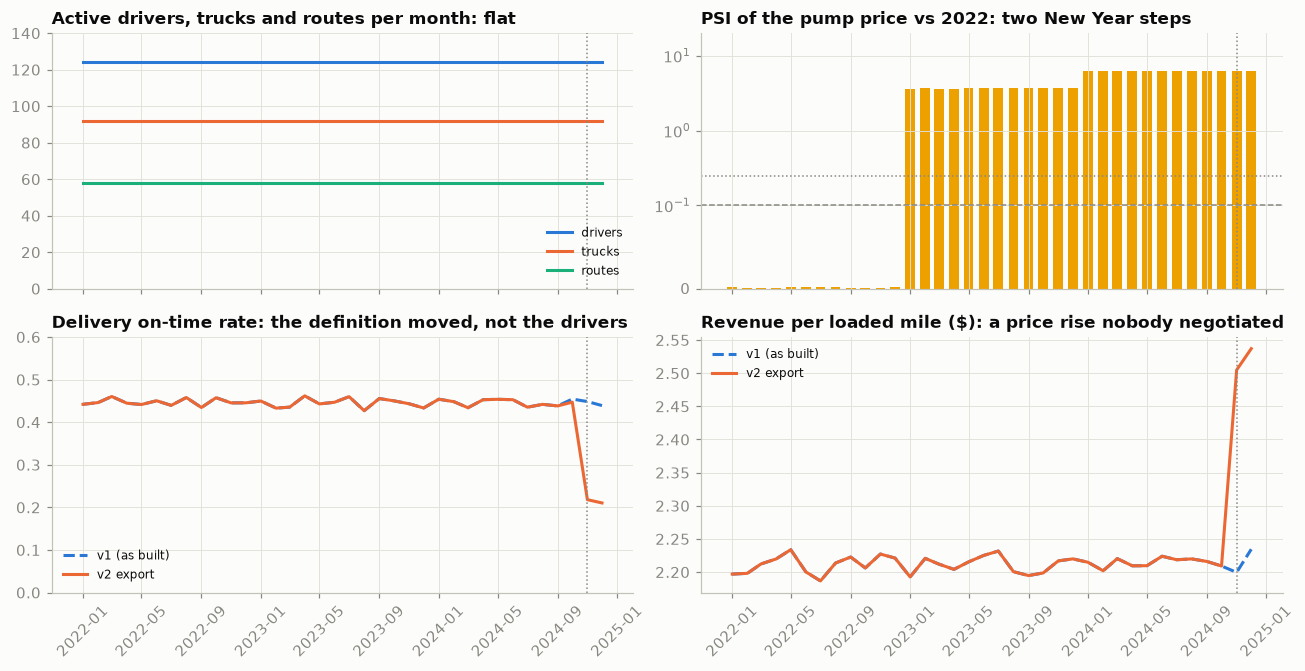

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.2), sharex=True)
tm = monthly.index
ax = axes[0, 0]
for col, color in zip(["drivers", "trucks", "routes"], SERIES):
    ax.plot(tm, monthly[col], lw=2, color=color, label=col)
ax.set_ylim(0, 140); ax.set_title("Active drivers, trucks and routes per month: flat"); ax.legend(fontsize=8, loc="lower right")
ax = axes[0, 1]
ax.bar(tm, monthly.psi_price, width=20, color=SERIES[3])
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_yscale("symlog", linthresh=0.1); ax.set_ylim(0, 20); ax.set_title("PSI of the pump price vs 2022: two New Year steps")
ax = axes[1, 0]
ax.plot(tm, monthly.ontime_v1, lw=2, color=SERIES[0], ls="--", label="v1 (as built)")
ax.plot(tm, monthly.ontime_v2, lw=2, color=SERIES[1], label="v2 export")
ax.set_ylim(0, 0.6); ax.set_title("Delivery on-time rate: the definition moved, not the drivers"); ax.legend(fontsize=8, loc="lower left")
ax = axes[1, 1]
ax.plot(tm, monthly.rpm_v1, lw=2, color=SERIES[0], ls="--", label="v1 (as built)")
ax.plot(tm, monthly.rpm_v2, lw=2, color=SERIES[1], label="v2 export")
ax.set_title("Revenue per loaded mile ($): a price rise nobody negotiated"); ax.legend(fontsize=8, loc="upper left")
for a in axes.ravel():
    a.axvline(SCHEMA_V2_FROM, color=MUTED, ls=":", lw=1); a.tick_params(axis="x", rotation=45)
plt.tight_layout()

The fleet and network do not drift at all, which corrects the card's expected 2024 fleet and route changes. The pump price moves twice, each New Year, with PSI far above the 0.25 alert line — the drift that broke M1. In November the v2 export shows on-time performance falling from 44.8 % to 21.8 % and revenue per mile rising from $2.20 to $2.51, with no operational cause; a dashboard would report both as news. The contract checks, the `RateCard` and `OnTimeDefinition` rules, fire on 49.9 % of November's loads and 23.0 % of its deliveries.

**The build gate on the new export.** Build with the frozen v1 mapping, then v1.1 (rename mapped), validate, and run the CQ suite against frozen v1 answers.

In [25]:
try:
    materialise(MAPPING_V1, schema="v2")
    print("mapping v1 on the v2 export: built (unexpected)")
except duckdb.Error as e:
    print(f"mapping v1 on the v2 export: build refused · {type(e).__name__}: {str(e).splitlines()[0][:110]}")
MAPPING_V1_1 = [dict(m, sql=m["sql"].replace("home_terminal, status", "home_terminal_city AS home_terminal, status")) if m["cls"] == "Truck" else m
                for m in MAPPING_V1]
t0 = time.time()
kg_v2 = materialise(MAPPING_V1_1, schema="v2", mapping_version="1.1")
viol_v2, _ = validate(kg_v2, ["RateCard", "OnTimeDefinition"])
print(f"mapping v1.1 (rename patched) · {len(kg_v2):,} triples · fingerprint {fingerprint(kg_v2)} (v1: {fingerprint(kg)}) · "
      f"build + 2 shapes in {time.time()-t0:.0f}s")
display(pd.DataFrame({"v1 graph": viol.loc[viol_v2.index, "violations"], "v2 graph": viol_v2.violations}))
cq_gate = run_cq_suite("v2", g=kg_v2)
print(f"CQ gate on the v2 graph (expected answers frozen from v1): {sum(same(a, b) for a, b in zip(cq_v1['expected (SQL)'], cq_gate['SPARQL']))}/10 pass · "
      f"failing: {[k for k, a, b in zip(cq_v1.index, cq_v1['expected (SQL)'], cq_gate['SPARQL']) if not same(a, b)]}")

mapping v1 on the v2 export: build refused · BinderException: Binder Error: Referenced column "home_terminal" not found in FROM clause!


mapping v1.1 (rename patched) · 274,101 triples · fingerprint 4573ab629f43 (v1: c29eaf9c847b) · build + 2 shapes in 21s


,v1 graph,v2 graph
RateCard,0,2398
OnTimeDefinition,0,1099


CQ gate on the v2 graph (expected answers frozen from v1): 8/10 pass · failing: ['CQ2', 'CQ3']


Three catches. The mapping refuses to build on a missing column; patched in one place, every SPARQL consumer keeps working (CQ6 passes on the graph although its SQL broke). The shapes flag the silent changes on the first night (2,398 loads off the rate card, 1,099 deliveries contradicting the ±120-minute rule), and the CQ gate fails on exactly the two questions whose meaning moved. None can say whether v2 is *wrong* — the business may have meant to tighten the SLA — so the monitoring plan must route it to the definition's owner (tasks C5 and S3).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's table, updated with what this notebook found: each row names an artefact for your repository and the number that judges it.

| Spine | In this project (after this notebook) |
|---|---|
| Package and container (S02–S03) | `src/fleet_kg/` (mapping, build, shapes, CQ suite, parser); `POST /ask` with refusal and clarification; `POST /predict/fuel-cost`, not `/predict/late` |
| Monitoring (S04) | Violations per shape per build (0 on the contract shapes; alert on any); build time; refusal rate (73.8 % on unseen phrasing); latency; price PSI |
| CI/CD gate (S05) | On a frozen, fingerprinted export: contract shapes at 0, CQs matching frozen answers (10/10 today), 2024 fuel bias within ±2 % and MAE under M0's $66.2 |
| MLflow tracking and registry (S06) | Each KG build is a run (versions, 274,101 triples, fingerprint, violations, CQ pass rate); M2 as `champion`, M0 as fallback |
| Offline / online training and serving | Nightly rebuild; online `/ask` and fuel-cost scoring; the model refreshes on a price-regime change, not a calendar |
| Data and model drift | No fleet or route drift; price PSI steps each New Year; November 2024 schema change: contract violations 0 → 49.9 % (rate card) and 23.0 % (on-time) |
| Knowledge base and context (S07–S09) | The graph is the deliverable. Ablation: parser with and without KG vocabulary (26.2 % held-out without); text-to-SQL against text-to-SPARQL on the CQ set |
| GenAI and context engineering (S10–S11) | NL → SQL or SPARQL with an LLM, verified by re-running against the CQ suite and golden set |
| Governance | Synthetic, MIT; driver and fuel-card fields dropped on load; driver-level questions are worker monitoring (task E2) |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** Validity-dated joins; grain-safe aggregation (revenue invariant under joins); an as-of test against post-trip and same-month features; frozen CQ answers. An ADR says whether the build quarantines, flags or blocks what the broken shapes report.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `WRONG_ANSWER_COST_USD` ($50–$1,000), analyst time and question volume; choose the policy for ambiguous names, out-of-window questions and the route; record the assumption and its sign-off in an ADR.
- **C4 — Package, container and CI gate.** `src/fleet_kg/`, a container serving both endpoints, and `make ci` that refuses to run if the export's or the 2024 holdout's SHA-256 fingerprint changes, and fails on any contract-shape violation, CQ mismatch or fuel bias outside ±2 % (Sessions 02, 03, 05).
- **C5 — MLflow, registry, model card, monitoring plan.** Log every KG build and fuel-model run; register M2 as `champion`; write the model card (synthetic provenance, formula artefacts, why no late model) and a monitoring plan: contract violations and CQ changes block publication and go to the definition's owner, price PSI above 0.25 triggers a refresh (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** Put the vocabulary in the graph (`rdfs:label`, `skos:altLabel` for intents, measures, lanes, makes, periods) and let the parser read it. With a fresh held-out set written first, report accuracy, failure modes and latency with and without KG context, and text-to-SQL against text-to-SPARQL on the CQ set (Sessions 07–09).
- **E2 — Governance: drivers are workers.** Driver-level questions evaluate identifiable workers: argue the EU AI Act (Annex III, point 4) and GDPR (Article 88) position, decide who may ask them, and check whether refusal rates differ across terminals.
- **E3 — Entity resolution.** Disambiguating labels for the 153 customers that share names; measure one-turn clarification success.
- **E4 — Time-valid modelling done properly.** OWL-Time, and contract intervals for customers (simulate end dates for the 32 "Inactive" ones); show which answers change.

### Stretch

- **S1 — GenAI: NL to SQL or SPARQL, verified.** An LLM given the ontology and three examples returns `{route, query, answer}`; re-run the query, compare with the CQ suite and golden set, refuse on disagreement. Report accuracy against this parser, the same-answer-twice rate over five samples, prompt-injection tests and cost per answer (Sessions 10–11).
- **S2 — Online serving at fleet scale.** Three years in the graph: rdflib against a triple store or Neo4j/Cypher on memory and p95 latency; nightly rebuild against incremental updates, costed.
- **S3 — Schema-change drill.** A v3 export with one more silent change: which monitor fires first?

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; driver and fuel-card fields never loaded
- [ ] `README.md` states the source (Kaggle, MIT, synthetic), the windows and how to get the data
- [ ] Mapping, shapes and CQ suite versioned; fingerprint and violations logged per build
- [ ] Validity-dated joins and grain-safe aggregation, each tested; no post-trip or same-month features
- [ ] `POST /ask` with refusal and clarification; operating point with its ADR
- [ ] CI with shapes, frozen CQ answers and the 2024 fuel gate; registered model and model card; monitoring plan that catches the November 2024 change
- [ ] One-page stakeholder recommendation, including who owns each definition
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `duckdb`, `rdflib`, `pyshacl`, `lightgbm`, `scikit-learn`, `matplotlib`, `kagglehub`; no LLM.
- Rodriguez, Y. (2025). *Logistics Operations Database.* Kaggle, MIT licence.
- Das, S., Sundara, S., Cyganiak, R. (2012). *R2RML: RDB to RDF Mapping Language.* W3C Recommendation.
- Knublauch, H., Kontokostas, D. (2017). *Shapes Constraint Language (SHACL).* W3C Recommendation.
- Grüninger, M., Fox, M. S. (1995). *Methodology for the Design and Evaluation of Ontologies.*
- Hogan, A. et al. (2021). *Knowledge Graphs.* ACM Computing Surveys 54(4).
- Kimball, R., Ross, M. (2013). *The Data Warehouse Toolkit*, 3rd ed. (slowly changing dimensions; fan traps).
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 and 8 (leakage; distribution shifts).

In [26]:
print(f"python packages · pandas {pd.__version__} · duckdb {duckdb.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__} · "
      f"lightgbm {lgb.__version__} · numpy {np.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python packages · pandas 3.1.0 · duckdb 2.0.0 · rdflib 7.6.0 · pyshacl 0.40.1 · lightgbm 4.7.0 · numpy 2.5.4
notebook finished · total wall time 128s
